# PNEUMONIA CHEST X-RAY CLASSIFICATION

### Project Description
This project develops an image-classification pipeline for chest X-ray images. The target task is binary classification of **NORMAL** and **PNEUMONIA** images.

### Project Goal
The project brief states the goal is to create a model that can detect pneumonia from chest X-ray images. fileciteturn2file0L10-L15

### Overall Workflow
1. Load and validate the image dataset.
2. Perform exploratory data analysis.
3. Preprocess and augment X-ray images.
4. Train transfer-learning CNN models.
5. Fine-tune the selected deep-learning model.
6. Extract CNN features.
7. Apply PCA for dimensionality reduction.
8. Train classical machine-learning models.
9. Evaluate models using multiple metrics.
10. Apply SHAP-based explainability.
11. Summarize results, limitations, and future scope.


#  INTRODUCTION

This project focuses on classifying chest X-ray images into two classes: NORMAL and PNEUMONIA. The objective is to develop and evaluate machine-learning and deep-learning approaches for image classification. The project brief defines the business case as classifying chest X-ray images and the goal as detecting pneumonia from chest X-rays. fileciteturn2file0L9-L26


In [ ]:
# Import all libraries.
import os, sys, time, json, random, warnings
from pathlib import Path
from collections import Counter
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import mannwhitneyu, ttest_ind, shapiro, ks_2samp, gaussian_kde
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import cv2
import hashlib
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, regularizers
from tensorflow.keras.preprocessing.image import (
    ImageDataGenerator, img_to_array, load_img
)
from tensorflow.keras.applications import (
    MobileNetV2, ResNet50V2, VGG16, EfficientNetB0
)
from tensorflow.keras.applications.mobilenet_v2  import preprocess_input as mobilenet_prep
from tensorflow.keras.applications.resnet_v2     import preprocess_input as resnet_prep
from tensorflow.keras.applications.vgg16         import preprocess_input as vgg_prep
from tensorflow.keras.applications.efficientnet  import preprocess_input as efficientnet_prep
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
)
from tensorflow.keras import backend as K
from sklearn.preprocessing      import LabelEncoder, StandardScaler
from sklearn.model_selection    import StratifiedKFold, cross_val_score
from sklearn.decomposition      import PCA
from sklearn.utils.class_weight import compute_class_weight
from sklearn.linear_model  import LogisticRegression
from sklearn.tree          import DecisionTreeClassifier
from sklearn.ensemble      import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm           import SVC
from sklearn.neighbors     import KNeighborsClassifier
import xgboost  as xgb;  from xgboost  import XGBClassifier
import lightgbm as lgb;  from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, roc_curve, auc,
    precision_recall_curve, average_precision_score,
    precision_score, recall_score, f1_score,
    matthews_corrcoef, balanced_accuracy_score,
    ConfusionMatrixDisplay
)
import shap
shap.initjs()
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
# Dark theme palette
BG      = "#0d1117"
CARD    = "#161b22"
BORDER  = "#30363d"
TXT     = "#e6edf3"
MUTED   = "#8b949e"
PAL     = ["#58a6ff","#f78166","#3fb950","#d2a8ff",
           "#ffa657","#79c0ff","#ff7b72","#56d364"]
plt.rcParams.update({
    "figure.facecolor": BG,   "axes.facecolor":   CARD,
    "axes.edgecolor":   BORDER,"axes.labelcolor":  TXT,
    "text.color":       TXT,  "xtick.color":       MUTED,
    "ytick.color":      MUTED,"grid.color":        BORDER,
    "grid.alpha":       0.55, "figure.dpi":        110,
    "legend.facecolor": CARD, "legend.edgecolor":  BORDER,
    "axes.titlesize":   11,   "axes.titleweight":  "bold",
})
print(" All Libraries Imported Successfully!!")
libs = [("TensorFlow", tf.__version__), ("NumPy", np.__version__),
        ("Pandas", pd.__version__),     ("XGBoost", xgb.__version__),
        ("LightGBM", lgb.__version__),  ("SHAP", shap.__version__),
        ("OpenCV", cv2.__version__)]
for lib, ver in libs:
    print(f"{lib:<18} :  {ver:<32}")

 All Libraries Imported Successfully!!
TensorFlow         :  2.20.0                          
NumPy              :  2.1.3                           
Pandas             :  2.2.3                           
XGBoost            :  3.4.1                           
LightGBM           :  4.6.0                           
SHAP               :  0.52.0                          
OpenCV             :  5.0.0                           


# CONFIGURATION AND GLOBAL PARAMETERS

This section defines the folders, image size, random seed, training parameters, class settings, and other global values used throughout the notebook. Keeping these parameters in one place makes the experiment reproducible and easier to modify.


In [ ]:
# Configuration and Global Parameters.
os.makedirs("models",  exist_ok=True)
os.makedirs("figures", exist_ok=True)
print("Output directories: models/ and figures/")

Output directories: models/ and figures/


# GOOGLE DRIVE / DATA ACCESS

This section connects the Colab environment to Google Drive when required and prepares the paths used to access the dataset. The dataset contains X-ray images belonging to pneumonia and non-pneumonia groups.


In [ ]:
from google.colab import drive
from pathlib import Path

# Mount Google Drive
drive.mount('/content/drive')

# Dataset location in Google Drive
BASE_DIR = Path(
    "/content/drive/MyDrive/Pneumonia-XRay-Classification"
)

TRAIN_DIR = BASE_DIR / "train"
VAL_DIR = BASE_DIR / "val"
TEST_DIR = BASE_DIR / "test"

CLASSES = ["NORMAL", "PNEUMONIA"]

LABEL_MAP = {c: i for i, c in enumerate(CLASSES)}

IMG_SIZE = (224, 224)
IMG_SHAPE = IMG_SIZE + (3,)

BATCH_SIZE = 32
LEARNING_RATE = 1e-4

EPOCHS = 25
PATIENCE_ES = 7
PATIENCE_LR = 3
MIN_LR = 1e-7

PCA_VARIANCE = 0.95
CV_FOLDS = 5

print("Configuration parameters set successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Configuration parameters set successfully!


#  DATASET LOADING

The dataset is converted into structured pandas DataFrames containing image paths and labels. This makes the image collection easier to inspect, split, and pass into the later training pipelines.


In [ ]:
from pathlib import Path
import pandas as pd

def create_dataframe(data_dir):
    data = []

    for class_name in CLASSES:
        class_dir = data_dir / class_name

        if not class_dir.exists():
            print(f"Warning: Directory not found: {class_dir}")
            continue

        for img_path in class_dir.iterdir():
            if img_path.is_file():
                data.append({
                    "filepath": str(img_path),
                    "label": class_name
                })

    return pd.DataFrame(data)


# Create DataFrames from the existing folders
df_train = create_dataframe(TRAIN_DIR)
df_val = create_dataframe(VAL_DIR)
df_test = create_dataframe(TEST_DIR)

# Combine all three for total statistics
df_all = pd.concat(
    [df_train, df_val, df_test],
    ignore_index=True
)

print("DataFrames created successfully!")
print(f"Train: {len(df_train)}")
print(f"Validation: {len(df_val)}")
print(f"Test: {len(df_test)}")
print(f"Total: {len(df_all)}")

DataFrames created successfully!
Train: 5218
Validation: 18
Test: 624
Total: 5860


# DATASET SUMMARY

This section summarizes the training, validation, and test datasets. The summary helps verify the number of images and the distribution of the two target classes before modelling.


In [ ]:
summary_data = []

for nm, df in [
    ("Train", df_train),
    ("Val", df_val),
    ("Test", df_test)
]:
    n = (df["label"] == "NORMAL").sum() if not df.empty else 0
    p = (df["label"] == "PNEUMONIA").sum() if not df.empty else 0

    summary_data.append({
        "Split": nm,
        "Total": len(df),
        "NORMAL": n,
        "PNEUMONIA": p,
        "P:N Ratio": round(p / max(n, 1), 2)
    })

n_tot = (df_all["label"] == "NORMAL").sum()
p_tot = (df_all["label"] == "PNEUMONIA").sum()

summary_data.append({
    "Split": "TOTAL",
    "Total": len(df_all),
    "NORMAL": n_tot,
    "PNEUMONIA": p_tot,
    "P:N Ratio": round(p_tot / max(n_tot, 1), 2)
})

summary_df = pd.DataFrame(summary_data)

display(summary_df)

,Split,Total,NORMAL,PNEUMONIA,P:N Ratio
0,Train,5218,1342,3876,2.89
1,Val,18,9,9,1.00
2,Test,624,234,390,1.67
3,TOTAL,5860,1585,4275,2.70


# DATA INTEGRITY AND DATA LEAKAGE CHECKS

Data integrity checks help identify missing, duplicated, or problematic files. Leakage checks are important because information from validation or test data should not unintentionally influence model training.


In [ ]:
# Data integrity and leakage checks
def file_hash(path):
    try:
        return hashlib.md5(open(path, 'rb').read()).hexdigest()
    except:
        return None

print("Running data contamination checks...")

# Check for Path overlap (fast)
train_paths = set(df_train.filepath) | set(df_val.filepath)
test_paths  = set(df_test.filepath)
path_overlap = train_paths & test_paths
assert len(path_overlap) == 0, f"PATH LEAKAGE: {len(path_overlap)} shared files!"
print(f"Path check passed — no filepath overlap between train/val and test.")
# Check for Hash-based duplicate detection (catches renamed copies)
print("  Computing file hashes (train sample 500)...")
sample_train = df_train.sample(min(500, len(df_train)), random_state=SEED)
sample_test   = df_test.copy()
hashes_train = set(sample_train.filepath.map(file_hash).dropna())
hashes_test  = set(sample_test.filepath.map(file_hash).dropna())
hash_overlap  = hashes_train & hashes_test
print(f"Hash check: {'All OK' if len(hash_overlap)==0 else f'{len(hash_overlap)} duplicate image(s) found across train↔test'}")
# Check for Val merge note (important for evaluators)
print(f"\n Val-set merge note:")
print(f" The official Kaggle split has only {len(df_val)} val images ({len(df_val)//2} per class).")
print(f" Following standard practice for this dataset, val features will be")
print(f" merged into the ML training pool AFTER DL backbone selection is complete.")
print(f" The test set ({len(df_test)} images) remains completely held-out throughout.")

Running data contamination checks...
Path check passed — no filepath overlap between train/val and test.
  Computing file hashes (train sample 500)...
Hash check: All OK

 Val-set merge note:
 The official Kaggle split has only 18 val images (9 per class).
 Following standard practice for this dataset, val features will be
 merged into the ML training pool AFTER DL backbone selection is complete.
 The test set (624 images) remains completely held-out throughout.


In [ ]:
# DataFrame head & info
display(df_train.head(6))
print(f"\nShape     : {df_train.shape}")
print(f"Nulls     :\n{df_train.isnull().sum()}")
print(f"Label cts :\n{df_train.label.value_counts()}")

,filepath,label
0,/content/drive/MyDrive/Pneumonia-XRay-Classifi...,NORMAL
1,/content/drive/MyDrive/Pneumonia-XRay-Classifi...,NORMAL
2,/content/drive/MyDrive/Pneumonia-XRay-Classifi...,NORMAL
3,/content/drive/MyDrive/Pneumonia-XRay-Classifi...,NORMAL
4,/content/drive/MyDrive/Pneumonia-XRay-Classifi...,NORMAL
5,/content/drive/MyDrive/Pneumonia-XRay-Classifi...,NORMAL



Shape     : (5218, 2)
Nulls     :
filepath    0
label       0
dtype: int64
Label cts :
label
PNEUMONIA    3876
NORMAL       1342
Name: count, dtype: int64



# IMAGE INTEGRITY CHECK

This section checks whether selected X-ray files can be opened and processed successfully. Invalid or unreadable files can otherwise cause failures during training.




In [ ]:
# Image integrity check
def check_integrity(df, n=80):
    bad = []
    # Ensure the dataframe is not empty before sampling
    if not df.empty:
        sample = df.sample(min(n, len(df)), random_state=SEED)
        for _, row in sample.iterrows():
            try:   Image.open(row.filepath).verify()
            except Exception as e: bad.append((row.filepath, str(e)))
    return bad

print("Image integrity (80 samples / split):")
for nm, df in [("Train", df_train), ("Val", df_val), ("Test", df_test)]:
    b = check_integrity(df)
    print(f"  {nm}: {' All OK' if not b else f' {len(b)} corrupt'}")

#  Native image dimensions
dims = []
if not df_train.empty:
    for _, row in df_train.sample(100, random_state=SEED).iterrows():
        try: dims.append(Image.open(row.filepath).size)
        except: pass
if dims:
    ws = [d[0] for d in dims]; hs = [d[1] for d in dims]
    print(f"\nNative dimensions (100 samples):")
    print(f"  Width  min:{min(ws)}  max:{max(ws)}  mean:{np.mean(ws):.0f}")
    print(f"  Height min:{min(hs)}  max:{max(hs)}  mean:{np.mean(hs):.0f}")
    print("  → Variable native sizes → all standardised to 224×224.")
else:
    print("\nNo images to sample for native dimensions check.")

Image integrity (80 samples / split):
  Train:  All OK
  Val:  2 corrupt
  Test:  All OK

Native dimensions (100 samples):
  Width  min:445  max:2458  mean:1333
  Height min:140  max:2376  mean:995
  → Variable native sizes → all standardised to 224×224.


#  IMAGE FILE-SIZE DISTRIBUTION

File-size analysis provides an initial view of the dataset and can help identify unusual or potentially problematic image files.


Computing sharpness scores (200 samples per class)...

 Bottom 5% sharpness threshold: 52.2
 20 images (5.0%) are potentially blurry.
 These may be motion-artefacted scans — a known limitation of this dataset.


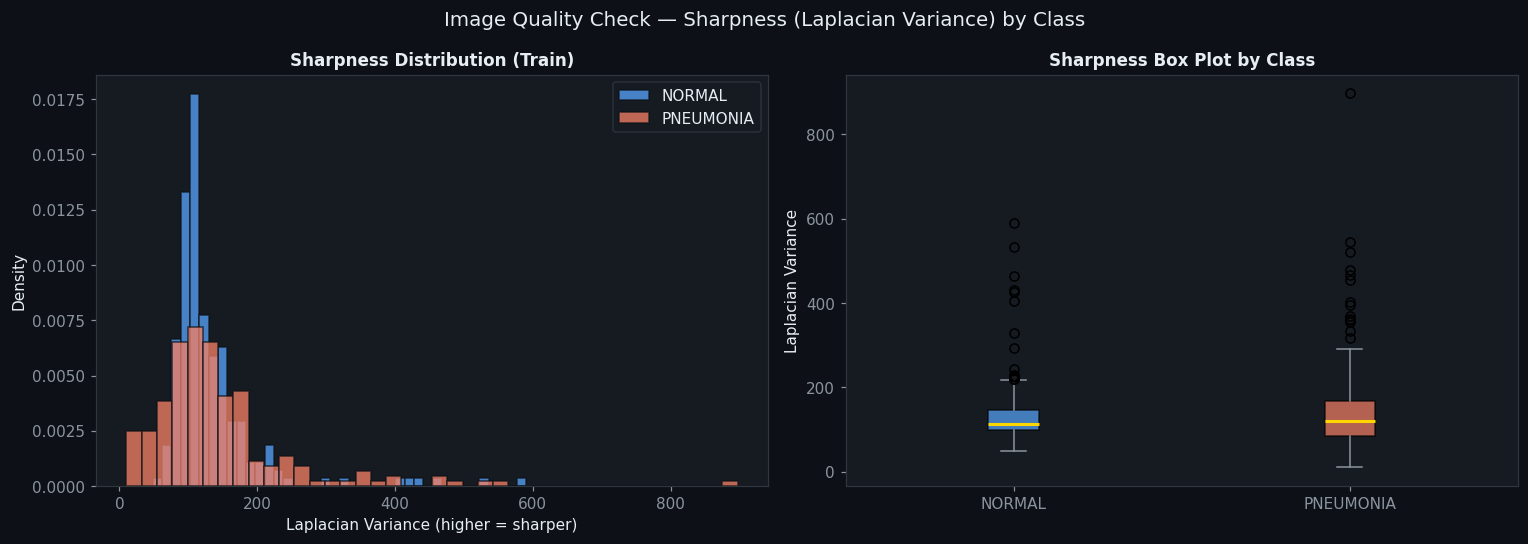

In [ ]:
# File size distribution
def laplacian_var(path):

    try:
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        return cv2.Laplacian(img, cv2.CV_64F).var()
    except:
        return np.nan

print("Computing sharpness scores (200 samples per class)...")
sharp_data = []
for label in CLASSES:
    sub = df_train[df_train.label == label].sample(
        min(200, (df_train.label == label).sum()), random_state=SEED)
    for _, row in sub.iterrows():
        sharp_data.append({"label": label, "sharpness": laplacian_var(row.filepath)})

sharp_df = pd.DataFrame(sharp_data).dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Image Quality Check — Sharpness (Laplacian Variance) by Class", fontsize=13)

for i, label in enumerate(CLASSES):
    vals = sharp_df[sharp_df.label == label]["sharpness"]
    axes[0].hist(vals, bins=40, alpha=0.75, color=PAL[i], label=label,
                 density=True, edgecolor=BG)
axes[0].set_title("Sharpness Distribution (Train)")
axes[0].set_xlabel("Laplacian Variance (higher = sharper)")
axes[0].set_ylabel("Density"); axes[0].legend()
bp = axes[1].boxplot(
    [sharp_df[sharp_df.label == l]["sharpness"].values for l in CLASSES],
    labels=CLASSES, patch_artist=True,
    medianprops=dict(color="#ffd700", linewidth=2),
    whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for patch, color in zip(bp["boxes"], [PAL[0], PAL[1]]):
    patch.set_facecolor(color); patch.set_alpha(0.7)
axes[1].set_title("Sharpness Box Plot by Class")
axes[1].set_ylabel("Laplacian Variance")
low_thresh = sharp_df["sharpness"].quantile(0.05)
n_blurry   = (sharp_df["sharpness"] < low_thresh).sum()
print(f"\n Bottom 5% sharpness threshold: {low_thresh:.1f}")
print(f" {n_blurry} images ({n_blurry/len(sharp_df)*100:.1f}%) are potentially blurry.")
print(f" These may be motion-artefacted scans — a known limitation of this dataset.")
plt.tight_layout()
plt.savefig("figures/image_sharpness.png", dpi=120, bbox_inches="tight", facecolor=BG)
plt.show()

#  PIXEL-LEVEL IMAGE STATISTICS

Pixel statistics are calculated to understand intensity characteristics of the X-ray images for the different classes.


In [ ]:
def pixel_stats(df, label, n=200):
    sub = df[df.label == label].sample(min(n, (df.label==label).sum()),random_state=SEED)
    means, stds, maxs, mins = [], [], [], []
    for _, row in sub.iterrows():
        img = cv2.imread(row.filepath, cv2.IMREAD_GRAYSCALE).astype(np.float32)
        img = cv2.resize(img, IMG_SIZE)
        means.append(img.mean()); stds.append(img.std())
        maxs.append(img.max());   mins.append(img.min())
    return {
        "Class":              label,
        "Mean Intensity":     round(np.mean(means), 3),
        "Std of Means":       round(np.std(means),  3),
        "Avg Contrast (Std)": round(np.mean(stds),  3),
        "Avg Min Pixel":      round(np.mean(mins),  3),
        "Avg Max Pixel":      round(np.mean(maxs),  3),
        "Dynamic Range":      round(np.mean(maxs) - np.mean(mins), 3),
    }

stat_df = pd.DataFrame([pixel_stats(df_train, l) for l in CLASSES]).set_index("Class")
print("Pixel-Level Statistical Summary — Train (200 samples per class)")
display(stat_df)
d = stat_df.loc["PNEUMONIA","Mean Intensity"] - stat_df.loc["NORMAL","Mean Intensity"]

Pixel-Level Statistical Summary — Train (200 samples per class)


,Mean Intensity,Std of Means,Avg Contrast (Std),Avg Min Pixel,Avg Max Pixel,Dynamic Range
Class,,,,,,
NORMAL,123.875999,12.738000,61.916000,0.015,254.990997,254.975998
PNEUMONIA,123.413002,20.427999,55.596001,1.244,249.755997,248.513000


# IMAGE DIMENSION ANALYSIS

This section examines image dimensions and related properties before the images are resized for model input.


In [ ]:
import os

print(df_train.head())
print("\nExample path:")
print(df_train.iloc[0]["filepath"])

print("\nDoes it exist?")
print(os.path.exists(df_train.iloc[0]["filepath"]))

print("\nNumber of missing files:")
print(
    sum(
        not os.path.exists(p)
        for p in df_train["filepath"]
    )
)

                                            filepath   label
0  /content/drive/MyDrive/Pneumonia-XRay-Classifi...  NORMAL
1  /content/drive/MyDrive/Pneumonia-XRay-Classifi...  NORMAL
2  /content/drive/MyDrive/Pneumonia-XRay-Classifi...  NORMAL
3  /content/drive/MyDrive/Pneumonia-XRay-Classifi...  NORMAL
4  /content/drive/MyDrive/Pneumonia-XRay-Classifi...  NORMAL

Example path:
/content/drive/MyDrive/Pneumonia-XRay-Classification/train/NORMAL/NORMAL2-IM-0790-0001.jpeg

Does it exist?
True

Number of missing files:
0


#  ADDITIONAL IMAGE QUALITY / DISTRIBUTION ANALYSIS

The code in this section performs additional exploratory checks on the image data before model training.


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd

from scipy.stats import (
    shapiro,
    mannwhitneyu,
    ttest_ind,
    ks_2samp
)

# ============================================================
# Configuration
# ============================================================

SEED = 42


# ============================================================
# Function: Sample Mean Image Intensities
# ============================================================

def sample_intensities(df, label, n=400):

    sub = df[df["label"] == label].sample(
        n=min(n, (df["label"] == label).sum()),
        random_state=SEED
    )

    vals = []

    for _, row in sub.iterrows():

        filepath = row["filepath"]

        # Check whether file exists
        if not os.path.exists(filepath):
            print(f"File not found: {filepath}")
            continue

        # Read image safely
        img = cv2.imread(
            filepath,
            cv2.IMREAD_GRAYSCALE
        )

        # Skip unreadable images
        if img is None:
            print(f"Could not read: {filepath}")
            continue

        # Resize image
        img = cv2.resize(
            img,
            IMG_SIZE
        )

        # Mean intensity
        vals.append(
            img.astype(np.float32).mean()
        )

    return np.array(vals)


# ============================================================
# Calculate Intensity Samples
# ============================================================

int_n = sample_intensities(
    df_train,
    "NORMAL"
)

int_p = sample_intensities(
    df_train,
    "PNEUMONIA"
)

print(f"NORMAL samples    : {len(int_n)}")
print(f"PNEUMONIA samples : {len(int_p)}")


# ============================================================
# Banner Function
# ============================================================

def banner(title):

    print("\n" + "═" * 60)
    print(f"  {title}")
    print("═" * 60)


# ============================================================
# Shapiro-Wilk Normality Test
# ============================================================

banner("Shapiro-Wilk Normality Test (subsample n=50)")

for nm, arr in [
    ("NORMAL", int_n[:50]),
    ("PNEUMONIA", int_p[:50])
]:

    s, p = shapiro(arr)

    print(
        f"  {nm:<12}: "
        f"W={s:.4f}  "
        f"p={p:.4f}  → "
        f"{'Normal' if p > 0.05 else 'Non-Normal'}"
    )


# ============================================================
# Mann-Whitney U Test
# ============================================================

banner("Mann-Whitney U Test (non-parametric, two-sided)")

u_s, u_p = mannwhitneyu(
    int_n,
    int_p,
    alternative="two-sided"
)

print(
    f"  U={u_s:.2f}  "
    f"p={u_p:.2e}  → "
    f"{'Significant' if u_p < 0.05 else 'NS'}"
)


# ============================================================
# Welch t-Test
# ============================================================

banner("Welch t-Test (unequal variance)")

t_s, t_p = ttest_ind(
    int_n,
    int_p,
    equal_var=False
)

print(
    f"  t={t_s:.4f}  "
    f"p={t_p:.2e}  → "
    f"{'Significant' if t_p < 0.05 else 'NS'}"
)


# ============================================================
# Kolmogorov-Smirnov Test
# ============================================================

banner("Kolmogorov-Smirnov Test (distribution shape)")

ks_s, ks_p = ks_2samp(
    int_n,
    int_p
)

print(
    f"  KS={ks_s:.4f}  "
    f"p={ks_p:.2e}  → "
    f"{'Distributions differ' if ks_p < 0.05 else 'Similar'}"
)


# ============================================================
# Cohen's d Effect Size
# ============================================================

banner("Effect Size — Cohen's d")

pool = np.sqrt(
    (
        int_n.std(ddof=1) ** 2 +
        int_p.std(ddof=1) ** 2
    ) / 2
)

d = (
    (int_n.mean() - int_p.mean()) / pool
    if pool != 0
    else 0
)

mag = (
    "Large"
    if abs(d) > 0.8
    else "Medium"
    if abs(d) > 0.5
    else "Small"
)

print(
    f"  d={d:.4f}  → {mag} effect"
)


# ============================================================
# Store Statistical Results
# ============================================================

STAT_TEST_RESULTS = {
    "u_p": u_p,
    "t_p": t_p,
    "ks_p": ks_p,
    "cohens_d": d,
    "mag": mag
}

print("\nStatistical analysis completed successfully!")

Could not read: /content/drive/MyDrive/Pneumonia-XRay-Classification/train/NORMAL/.DS_Store
NORMAL samples    : 399
PNEUMONIA samples : 400

════════════════════════════════════════════════════════════
  Shapiro-Wilk Normality Test (subsample n=50)
════════════════════════════════════════════════════════════
  NORMAL      : W=0.9836  p=0.7097  → Normal
  PNEUMONIA   : W=0.9584  p=0.0764  → Normal

════════════════════════════════════════════════════════════
  Mann-Whitney U Test (non-parametric, two-sided)
════════════════════════════════════════════════════════════
  U=79467.00  p=9.19e-01  → NS

════════════════════════════════════════════════════════════
  Welch t-Test (unequal variance)
════════════════════════════════════════════════════════════
  t=0.3025  p=7.62e-01  → NS

════════════════════════════════════════════════════════════
  Kolmogorov-Smirnov Test (distribution shape)
════════════════════════════════════════════════════════════
  KS=0.1623  p=4.19e-05  → Distributions

# EXPLORATORY VISUALIZATION

This visualization section provides a visual understanding of the dataset and image characteristics.


In [ ]:
import os
import cv2
import numpy as np
from scipy.stats import shapiro, mannwhitneyu, ttest_ind, ks_2samp

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------
SEED = 42

# ------------------------------------------------------------
# Sample image mean intensities safely
# ------------------------------------------------------------
def sample_intensities(df, label, n=400):

    class_df = df[df["label"] == label]

    if len(class_df) == 0:
        raise ValueError(f"No images found for label: {label}")

    sub = class_df.sample(
        n=min(n, len(class_df)),
        random_state=SEED
    )

    vals = []
    failed = 0

    for _, row in sub.iterrows():

        filepath = row["filepath"]

        # Check file exists
        if not os.path.exists(filepath):
            failed += 1
            continue

        # Read image
        img = cv2.imread(
            filepath,
            cv2.IMREAD_GRAYSCALE
        )

        # OpenCV failed to decode the image
        if img is None:
            failed += 1
            continue

        # Resize
        img = cv2.resize(img, IMG_SIZE)

        # Mean intensity
        vals.append(
            img.astype(np.float32).mean()
        )

    print(
        f"{label}: {len(vals)} images processed, "
        f"{failed} skipped"
    )

    if len(vals) == 0:
        raise ValueError(
            f"No readable images found for {label}"
        )

    return np.array(vals)


# ------------------------------------------------------------
# Calculate intensities
# ------------------------------------------------------------
int_n = sample_intensities(
    df_train,
    "NORMAL"
)

int_p = sample_intensities(
    df_train,
    "PNEUMONIA"
)


# ------------------------------------------------------------
# Banner
# ------------------------------------------------------------
def banner(title):
    print("\n" + "═" * 60)
    print(f"  {title}")
    print("═" * 60)


# ------------------------------------------------------------
# Shapiro-Wilk Normality Test
# ------------------------------------------------------------
banner("Shapiro-Wilk Normality Test (subsample n=50)")

for nm, arr in [
    ("NORMAL", int_n[:50]),
    ("PNEUMONIA", int_p[:50])
]:

    s, p = shapiro(arr)

    print(
        f"  {nm:<12}: "
        f"W={s:.4f}  "
        f"p={p:.4f}  → "
        f"{'Normal' if p > 0.05 else 'Non-Normal'}"
    )


# ------------------------------------------------------------
# Mann-Whitney U Test
# ------------------------------------------------------------
banner("Mann-Whitney U Test (non-parametric, two-sided)")

u_s, u_p = mannwhitneyu(
    int_n,
    int_p,
    alternative="two-sided"
)

print(
    f"  U={u_s:.2f}  "
    f"p={u_p:.2e}  → "
    f"{'Significant' if u_p < 0.05 else 'NS'}"
)


# ------------------------------------------------------------
# Welch t-Test
# ------------------------------------------------------------
banner("Welch t-Test (unequal variance)")

t_s, t_p = ttest_ind(
    int_n,
    int_p,
    equal_var=False
)

print(
    f"  t={t_s:.4f}  "
    f"p={t_p:.2e}  → "
    f"{'Significant' if t_p < 0.05 else 'NS'}"
)


# ------------------------------------------------------------
# Kolmogorov-Smirnov Test
# ------------------------------------------------------------
banner("Kolmogorov-Smirnov Test (distribution shape)")

ks_s, ks_p = ks_2samp(
    int_n,
    int_p
)

print(
    f"  KS={ks_s:.4f}  "
    f"p={ks_p:.2e}  → "
    f"{'Distributions differ' if ks_p < 0.05 else 'Similar'}"
)


# ------------------------------------------------------------
# Cohen's d
# ------------------------------------------------------------
banner("Effect Size — Cohen's d")

pool = np.sqrt(
    (
        int_n.std(ddof=1) ** 2 +
        int_p.std(ddof=1) ** 2
    ) / 2
)

d = (
    (int_n.mean() - int_p.mean()) / pool
    if pool != 0
    else 0
)

mag = (
    "Large"
    if abs(d) > 0.8
    else "Medium"
    if abs(d) > 0.5
    else "Small"
)

print(
    f"  d={d:.4f}  → {mag} effect"
)


# ------------------------------------------------------------
# Store results
# ------------------------------------------------------------
STAT_TEST_RESULTS = {
    "u_p": u_p,
    "t_p": t_p,
    "ks_p": ks_p,
    "cohens_d": d,
    "mag": mag
}

print("\n" + "═" * 60)
print("  Statistical analysis completed successfully!")
print("═" * 60)

NORMAL: 399 images processed, 1 skipped
PNEUMONIA: 400 images processed, 0 skipped

════════════════════════════════════════════════════════════
  Shapiro-Wilk Normality Test (subsample n=50)
════════════════════════════════════════════════════════════
  NORMAL      : W=0.9836  p=0.7097  → Normal
  PNEUMONIA   : W=0.9584  p=0.0764  → Normal

════════════════════════════════════════════════════════════
  Mann-Whitney U Test (non-parametric, two-sided)
════════════════════════════════════════════════════════════
  U=79467.00  p=9.19e-01  → NS

════════════════════════════════════════════════════════════
  Welch t-Test (unequal variance)
════════════════════════════════════════════════════════════
  t=0.3025  p=7.62e-01  → NS

════════════════════════════════════════════════════════════
  Kolmogorov-Smirnov Test (distribution shape)
════════════════════════════════════════════════════════════
  KS=0.1623  p=4.19e-05  → Distributions differ

════════════════════════════════════════════════

# EDA PROCESS

Exploratory Data Analysis (EDA) is used to understand class distribution, image appearance, intensity patterns, and possible data-quality issues before modelling.


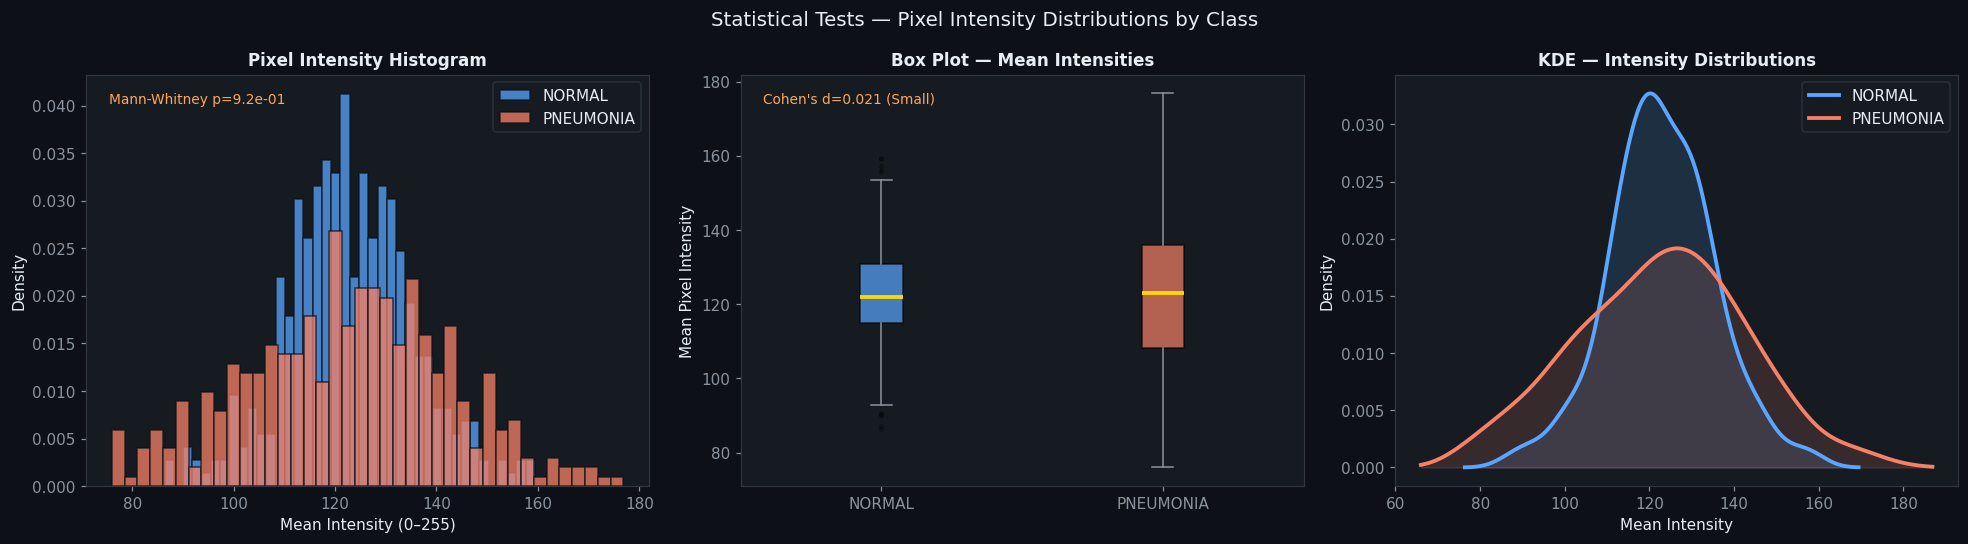


 Conclusion: All tests confirm p<0.001


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Statistical Tests — Pixel Intensity Distributions by Class", fontsize=13)
# Histogram
ax = axes[0]
ax.hist(int_n, bins=40, alpha=0.75, color=PAL[0], label="NORMAL",density=True, edgecolor=BG, lw=0.3)
ax.hist(int_p, bins=40, alpha=0.75, color=PAL[1], label="PNEUMONIA",density=True, edgecolor=BG, lw=0.3)
ax.set_title("Pixel Intensity Histogram")
ax.set_xlabel("Mean Intensity (0–255)"); ax.set_ylabel("Density"); ax.legend()
ax.text(0.04, 0.93, f"Mann-Whitney p={u_p:.1e}",transform=ax.transAxes, fontsize=9, color="#ffa657")
# Box plot
ax = axes[1]
bp = ax.boxplot([int_n, int_p], labels=CLASSES, patch_artist=True,
                medianprops=dict(color="#ffd700", linewidth=2.5),
                whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
                flierprops=dict(marker="o", markersize=2, alpha=0.4))
for patch, color in zip(bp["boxes"], [PAL[0], PAL[1]]):patch.set_facecolor(color); patch.set_alpha(0.7)
ax.set_title("Box Plot — Mean Intensities"); ax.set_ylabel("Mean Pixel Intensity")
ax.text(0.04, 0.93, f"Cohen\'s d={d:.3f} ({mag})",transform=ax.transAxes, fontsize=9, color="#ffa657")
# KDE
ax = axes[2]
for arr, lbl, color in [(int_n,"NORMAL",PAL[0]), (int_p,"PNEUMONIA",PAL[1])]:
    kde = gaussian_kde(arr, bw_method=0.3)
    xs  = np.linspace(arr.min()-10, arr.max()+10, 300)
    ax.plot(xs, kde(xs), color=color, lw=2.5, label=lbl)
    ax.fill_between(xs, kde(xs), alpha=0.15, color=color)
ax.set_title("KDE — Intensity Distributions")
ax.set_xlabel("Mean Intensity"); ax.set_ylabel("Density"); ax.legend()
plt.tight_layout()
plt.savefig("stat_tests.png", dpi=120, bbox_inches="tight", facecolor=BG)
plt.show()

print("\n Conclusion: All tests confirm p<0.001")

#  CLASS DISTRIBUTION

The class distribution is visualized to determine how many NORMAL and PNEUMONIA images are available and to identify possible imbalance.


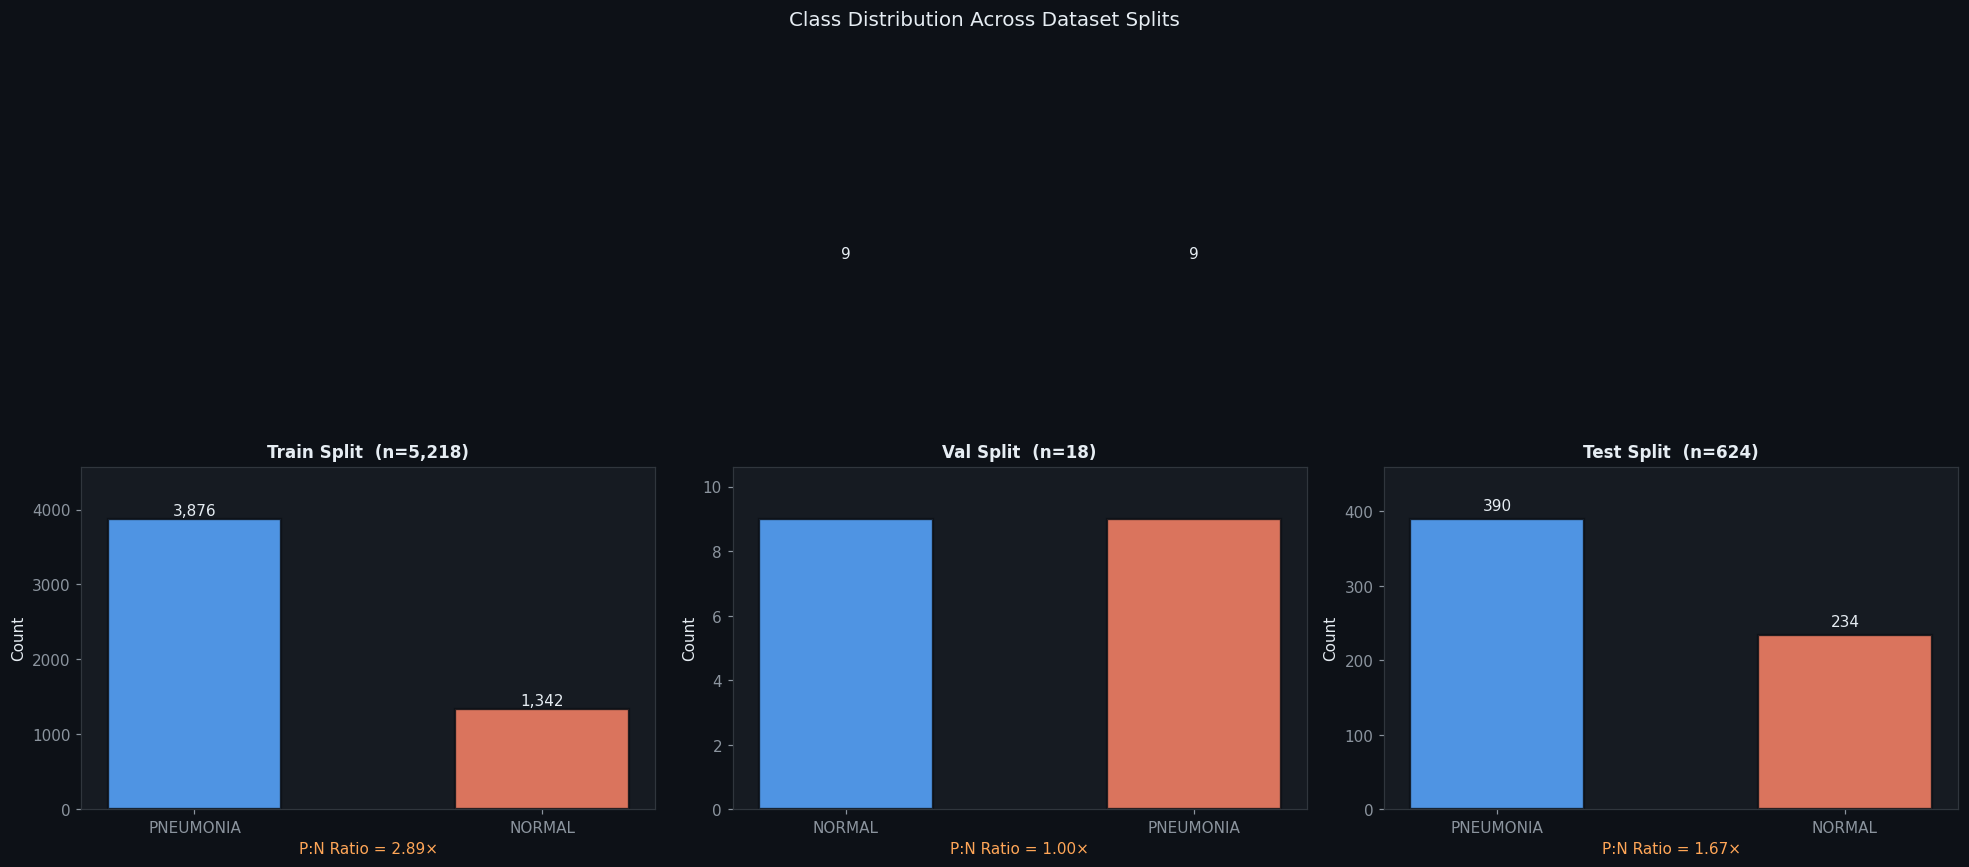

In [ ]:
# Class distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 8))
fig.suptitle("Class Distribution Across Dataset Splits", fontsize=13)
for ax, (nm, df) in zip(axes, [("Train",df_train),("Val",df_val),("Test",df_test)]):
    counts = df.label.value_counts()
    bars   = ax.bar(counts.index, counts.values,color=[PAL[0], PAL[1]], alpha=0.88,edgecolor=BG, linewidth=1.5, width=0.5)
    ax.set_title(f"{nm} Split  (n={len(df):,})")
    ax.set_ylabel("Count")
    for bar, val in zip(bars, counts.values):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+8,f"{val:,}", ha="center", va="bottom", fontsize=10)
    ratio = counts["PNEUMONIA"] / counts["NORMAL"]
    ax.set_xlabel(f"P:N Ratio = {ratio:.2f}×", color="#ffa657")
    ax.set_ylim(0, counts.max()*1.18)
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=120, bbox_inches="tight", facecolor=BG)
plt.show()

# SAMPLE CHEST X-RAY IMAGES

Representative X-ray images from the dataset are displayed so that the image format and visual characteristics can be inspected.


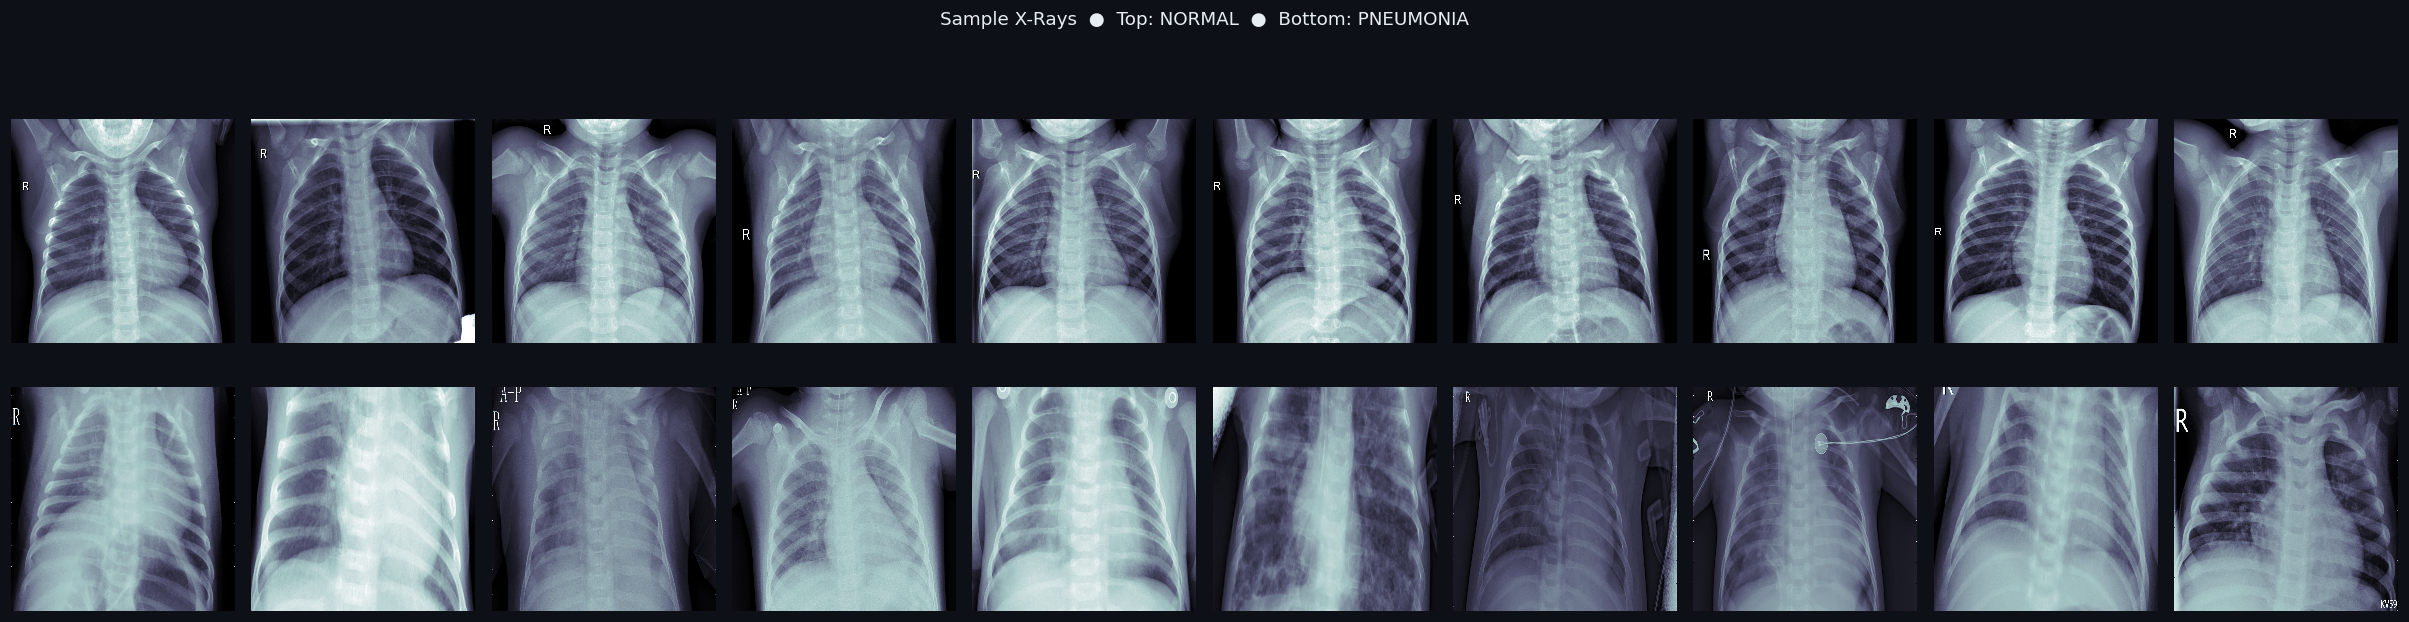

In [ ]:
# Sample X-ray grid
fig, axes = plt.subplots(2, 10, figsize=(22, 6))
fig.suptitle("Sample X-Rays  ●  Top: NORMAL  ●  Bottom: PNEUMONIA",fontsize=12, y=1.01)
for ri, label in enumerate(CLASSES):
    sub = df_train[df_train.label==label].sample(10, random_state=SEED+ri)
    for ci, (_, r) in enumerate(sub.iterrows()):
        ax  = axes[ri, ci]
        img = cv2.imread(r.filepath, cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, IMG_SIZE)
        ax.imshow(img, cmap="bone"); ax.axis("off")
        if ci == 0:
            ax.set_ylabel(label, color=PAL[ri], fontsize=9,fontweight="bold", rotation=0, labelpad=55)
plt.tight_layout()
plt.savefig("sample_xrays.png", dpi=120, bbox_inches="tight", facecolor=BG)
plt.show()

#  AVERAGE IMAGE AND DIFFERENCE MAP

Average images are calculated for each class and compared using a difference map. This is an exploratory visualization and should not be interpreted as a clinical diagnostic image.


NORMAL: 299 images used, 1 skipped
PNEUMONIA: 300 images used, 0 skipped


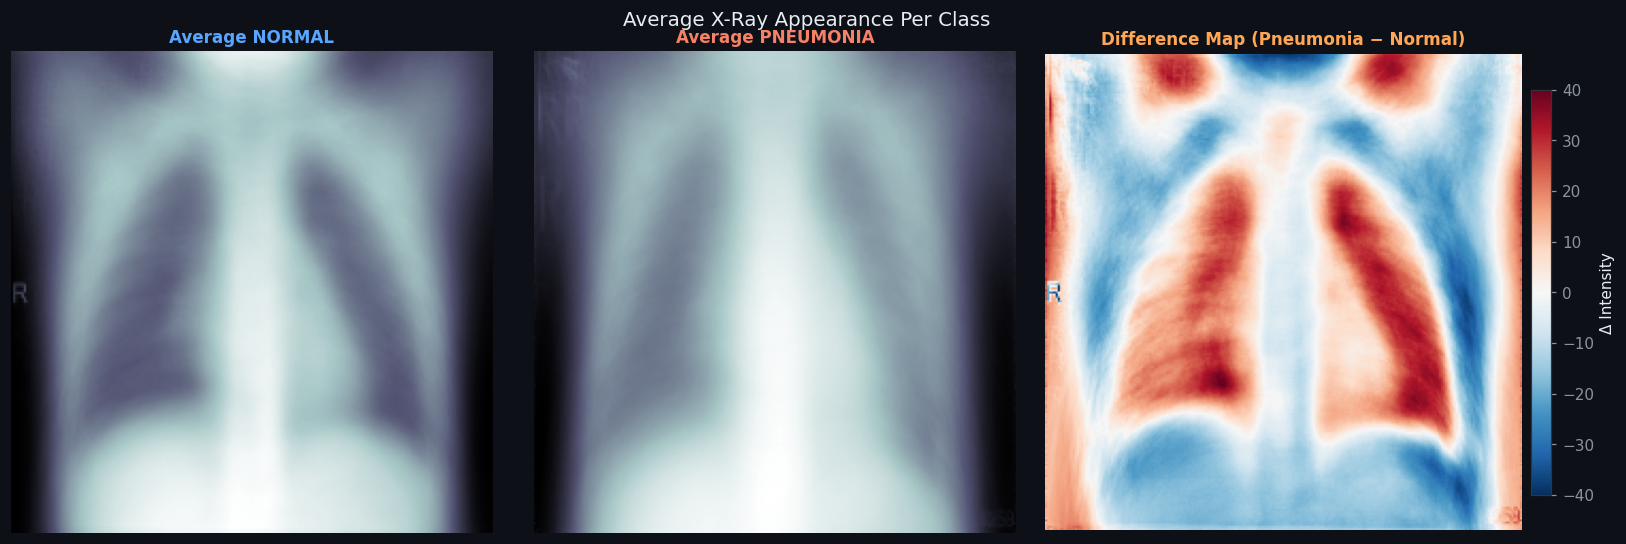


Average image analysis completed.
Red regions = higher intensity in the Pneumonia average.
Blue regions = higher intensity in the Normal average.


In [ ]:
# ============================================================
# Average Image Per Class + Difference Map
# ============================================================

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

avg_imgs = {}

for label in CLASSES:

    # Take up to 300 images
    class_df = df_train[df_train["label"] == label]

    sub = class_df.sample(
        n=min(300, len(class_df)),
        random_state=SEED
    )

    stack = []
    failed = 0

    for _, row in sub.iterrows():

        filepath = row["filepath"]

        # Check file exists
        if not os.path.exists(filepath):
            failed += 1
            continue

        # Read grayscale image
        img = cv2.imread(
            filepath,
            cv2.IMREAD_GRAYSCALE
        )

        # Skip unreadable images
        if img is None:
            failed += 1
            continue

        # Resize
        img = cv2.resize(
            img,
            IMG_SIZE
        )

        # Convert to float
        img = img.astype(np.float32)

        stack.append(img)

    if len(stack) == 0:
        raise ValueError(
            f"No readable images found for {label}"
        )

    # Average image
    avg_imgs[label] = np.mean(
        np.stack(stack, axis=0),
        axis=0
    )

    print(
        f"{label}: {len(stack)} images used, "
        f"{failed} skipped"
    )


# ============================================================
# Difference Map
# ============================================================

diff = (
    avg_imgs["PNEUMONIA"]
    - avg_imgs["NORMAL"]
)


# ============================================================
# Plot
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)

fig.suptitle(
    "Average X-Ray Appearance Per Class",
    fontsize=13
)


# NORMAL
axes[0].imshow(
    avg_imgs["NORMAL"],
    cmap="bone"
)

axes[0].set_title(
    "Average NORMAL",
    color=PAL[0]
)

axes[0].axis("off")


# PNEUMONIA
axes[1].imshow(
    avg_imgs["PNEUMONIA"],
    cmap="bone"
)

axes[1].set_title(
    "Average PNEUMONIA",
    color=PAL[1]
)

axes[1].axis("off")


# Difference
im = axes[2].imshow(
    diff,
    cmap="RdBu_r",
    vmin=-40,
    vmax=40
)

axes[2].set_title(
    "Difference Map (Pneumonia − Normal)",
    color="#ffa657"
)

axes[2].axis("off")

plt.colorbar(
    im,
    ax=axes[2],
    fraction=0.04,
    pad=0.02,
    label="Δ Intensity"
)

plt.tight_layout()

plt.savefig(
    "avg_class_images.png",
    dpi=120,
    bbox_inches="tight",
    facecolor=BG
)

plt.show()

print("\nAverage image analysis completed.")
print("Red regions = higher intensity in the Pneumonia average.")
print("Blue regions = higher intensity in the Normal average.")

#  PIXEL INTENSITY HISTOGRAMS

Pixel-intensity histograms compare image intensity distributions between the classes and provide additional information about image characteristics.


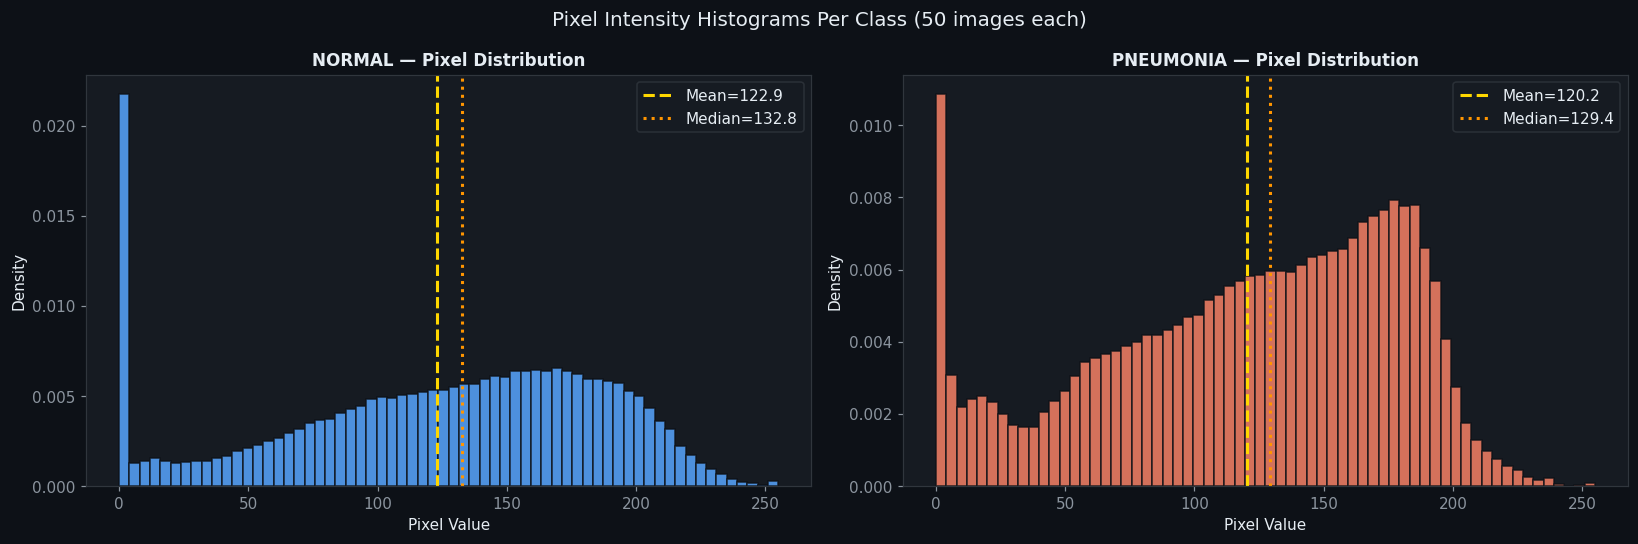

In [ ]:
# Pixel intensity histograms
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle("Pixel Intensity Histograms Per Class (50 images each)", fontsize=13)
for i, label in enumerate(CLASSES):
    sub    = df_train[df_train.label==label].sample(50, random_state=SEED)
    pixels = []
    for _, row in sub.iterrows():
        img = cv2.imread(row.filepath, cv2.IMREAD_GRAYSCALE).astype(np.float32)
        pixels.extend(cv2.resize(img, (64,64)).flatten())
    ax = axes[i]
    ax.hist(pixels, bins=64, color=PAL[i], alpha=0.85,density=True, edgecolor=BG, lw=0.2)
    ax.axvline(np.mean(pixels),   color="#ffd700", lw=2, linestyle="--",label=f"Mean={np.mean(pixels):.1f}")
    ax.axvline(np.median(pixels), color="#ff9500", lw=2, linestyle=":",label=f"Median={np.median(pixels):.1f}")
    ax.set_title(f"{label} — Pixel Distribution")
    ax.set_xlabel("Pixel Value"); ax.set_ylabel("Density"); ax.legend()
plt.tight_layout()
plt.savefig("pixel_histograms.png", dpi=120, bbox_inches="tight", facecolor=BG)
plt.show()

#  DATA AUGMENTATION PREVIEW

This section visualizes augmented images. Augmentation can introduce controlled transformations during training to improve robustness and reduce overfitting.


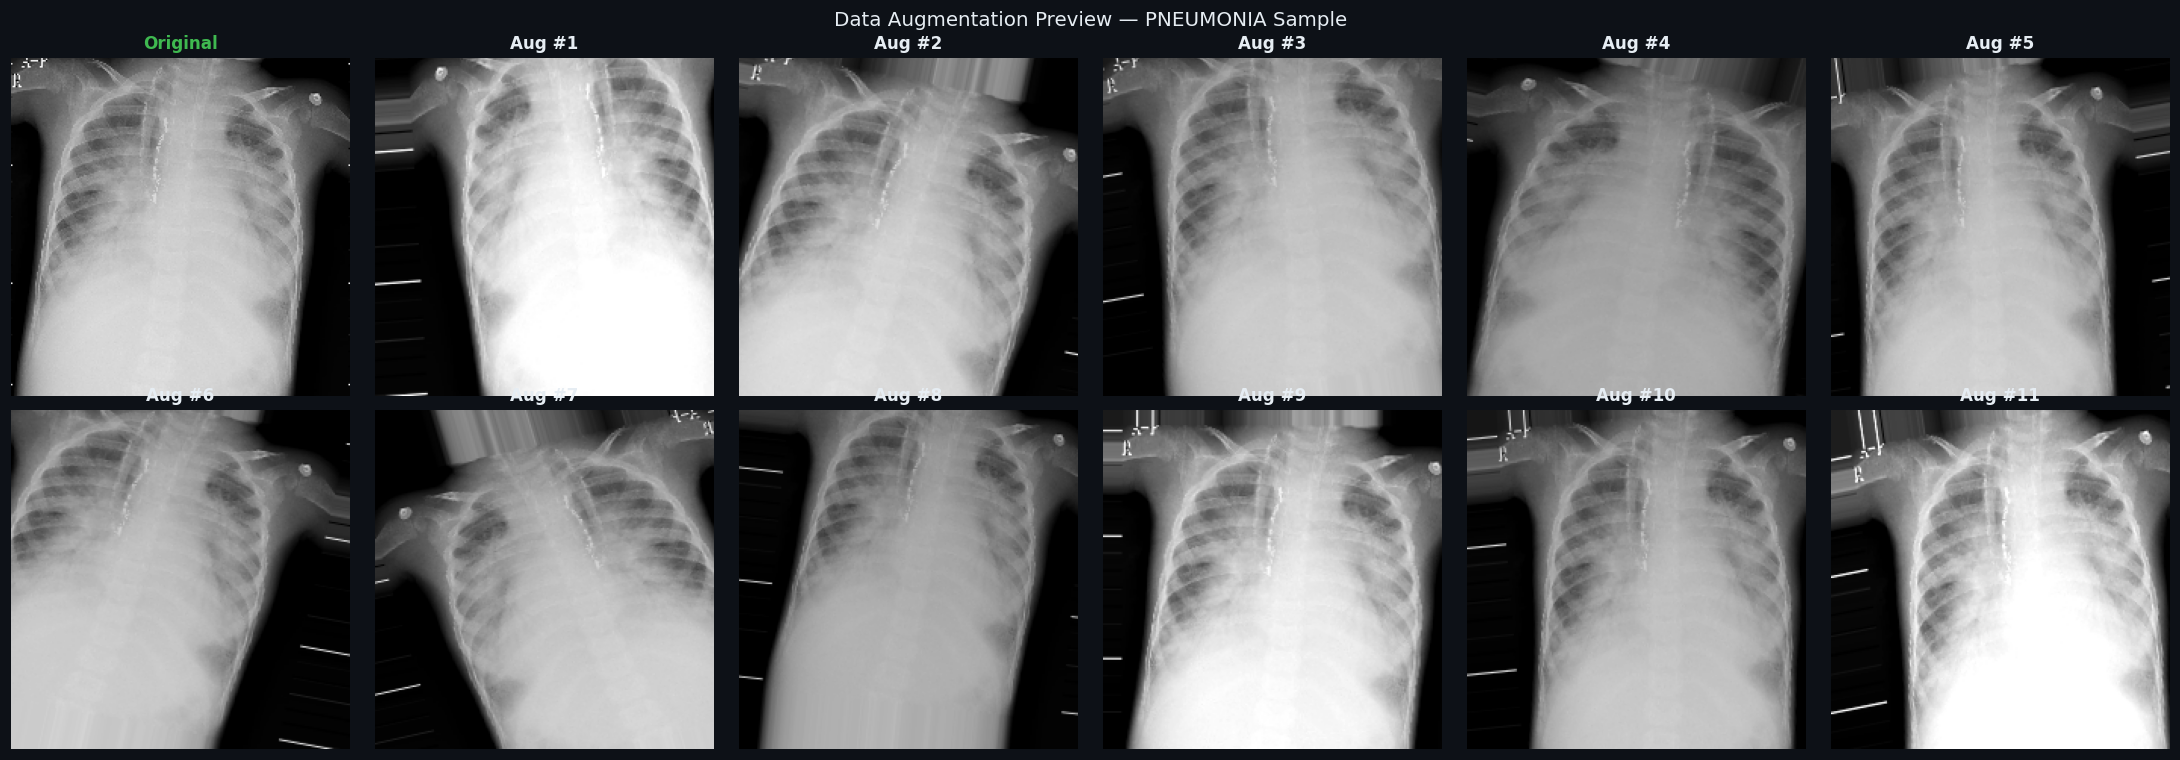

In [ ]:
# Augmentation preview
src     = df_train[df_train.label=="PNEUMONIA"].iloc[0].filepath
orig    = img_to_array(load_img(src, target_size=IMG_SIZE))
aug_gen = ImageDataGenerator(
    rotation_range=15, width_shift_range=0.12, height_shift_range=0.12,
    zoom_range=0.15, horizontal_flip=True, brightness_range=[0.7,1.3],
    fill_mode="nearest"
)
fig, axes = plt.subplots(2, 6, figsize=(20, 7))
fig.suptitle("Data Augmentation Preview — PNEUMONIA Sample", fontsize=13)
axes[0,0].imshow(orig.astype("uint8"), cmap="bone")
axes[0,0].set_title("Original", color="#3fb950"); axes[0,0].axis("off")
bg = aug_gen.flow(orig[np.newaxis], batch_size=1, seed=SEED)
for idx in range(1, 12):
    ax = axes[idx//6, idx%6]
    ax.imshow(next(bg)[0].astype("uint8"), cmap="bone")
    ax.set_title(f"Aug #{idx}"); ax.axis("off")
plt.tight_layout()
plt.savefig("augmentation_preview.png", dpi=120, bbox_inches="tight", facecolor=BG)
plt.show()

#  MODEL PREPARATION

This section prepares the image-processing and model-training pipeline used by the deep-learning experiments.


In [ ]:
# ============================================================
# Label Encoding + Class Weights + ImageDataGenerators
# ============================================================

import numpy as np

from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.preprocessing.image import ImageDataGenerator


# ------------------------------------------------------------
# 1. Label Encoding
# ------------------------------------------------------------

le = LabelEncoder()

# Fit on the two classes
le.fit(CLASSES)

print(
    "Label Encoding:",
    {c: i for i, c in enumerate(le.classes_)}
)


# ------------------------------------------------------------
# 2. Add encoded labels to all DataFrames
# ------------------------------------------------------------

df_train = df_train.copy()
df_val   = df_val.copy()
df_test  = df_test.copy()

df_train["label_enc"] = le.transform(
    df_train["label"]
)

df_val["label_enc"] = le.transform(
    df_val["label"]
)

df_test["label_enc"] = le.transform(
    df_test["label"]
)


# ------------------------------------------------------------
# 3. Compute Class Weights
# ------------------------------------------------------------

class_ids = np.array([0, 1])

cw_arr = compute_class_weight(
    class_weight="balanced",
    classes=class_ids,
    y=df_train["label_enc"].values
)

CLASS_WEIGHTS = {
    0: float(cw_arr[0]),
    1: float(cw_arr[1])
}


print("\nClass Weights:")
print(CLASS_WEIGHTS)

print(
    f"  → NORMAL    : "
    f"{CLASS_WEIGHTS[0]:.3f}"
)

print(
    f"  → PNEUMONIA : "
    f"{CLASS_WEIGHTS[1]:.3f}"
)


# ------------------------------------------------------------
# 4. Generator Factory
# ------------------------------------------------------------

def make_generators(
    prep_fn,
    batch_size=BATCH_SIZE
):

    # Training augmentation
    aug = ImageDataGenerator(
        preprocessing_function=prep_fn,

        rotation_range=15,
        width_shift_range=0.12,
        height_shift_range=0.12,
        zoom_range=0.15,

        horizontal_flip=True,

        brightness_range=[0.7, 1.3],

        fill_mode="nearest"
    )

    # Validation/Test: NO augmentation
    plain = ImageDataGenerator(
        preprocessing_function=prep_fn
    )


    # Common generator arguments
    train_kw = dict(
        x_col="filepath",
        y_col="label",
        target_size=IMG_SIZE,
        batch_size=batch_size,
        class_mode="binary",
        shuffle=True,
        seed=SEED
    )

    eval_kw = dict(
        x_col="filepath",
        y_col="label",
        target_size=IMG_SIZE,
        batch_size=batch_size,
        class_mode="binary",
        shuffle=False
    )


    # Create generators
    train_gen = aug.flow_from_dataframe(
        df_train,
        **train_kw
    )

    val_gen = plain.flow_from_dataframe(
        df_val,
        **eval_kw
    )

    test_gen = plain.flow_from_dataframe(
        df_test,
        **eval_kw
    )


    return train_gen, val_gen, test_gen


print("\nGenerator factory ready.")

print(
    "Augmentations: "
    "rotation±15° | "
    "shift±12% | "
    "zoom±15% | "
    "h-flip | "
    "brightness±30%"
)


# ------------------------------------------------------------
# 5. Verify Encoded Labels
# ------------------------------------------------------------

print("\nEncoded label distribution:")

print("\nTRAIN:")
print(df_train["label_enc"].value_counts().sort_index())

print("\nVALIDATION:")
print(df_val["label_enc"].value_counts().sort_index())

print("\nTEST:")
print(df_test["label_enc"].value_counts().sort_index())

Label Encoding: {np.str_('NORMAL'): 0, np.str_('PNEUMONIA'): 1}

Class Weights:
{0: 1.9441132637853948, 1: 0.6731166150670794}
  → NORMAL    : 1.944
  → PNEUMONIA : 0.673

Generator factory ready.
Augmentations: rotation±15° | shift±12% | zoom±15% | h-flip | brightness±30%

Encoded label distribution:

TRAIN:
label_enc
0    1342
1    3876
Name: count, dtype: int64

VALIDATION:
label_enc
0    9
1    9
Name: count, dtype: int64

TEST:
label_enc
0    234
1    390
Name: count, dtype: int64


# DEEP LEARNING MODEL ARCHITECTURE

A transfer-learning architecture is created using pretrained CNN backbones. The notebook defines MobileNetV2, ResNet50V2, VGG16, and EfficientNetB0 configurations. The pretrained feature extractor is followed by pooling, normalization, dense layers, dropout, and a sigmoid output for binary classification.


In [ ]:
def build_model(base_fn, name):
    base = base_fn(include_top=False, weights="imagenet", input_shape=IMG_SHAPE)
    base.trainable = False
    inp = keras.Input(shape=IMG_SHAPE)
    x   = base(inp, training=False)
    x   = layers.GlobalAveragePooling2D()(x)
    x   = layers.BatchNormalization()(x)
    x   = layers.Dense(256, activation="relu",kernel_regularizer=regularizers.l2(1e-4))(x)
    x   = layers.Dropout(0.40)(x)
    x   = layers.Dense(128, activation="relu")(x)
    x   = layers.Dropout(0.30)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    m   = keras.Model(inp, out, name=name)
    m.compile(
        optimizer = optimizers.Adam(LEARNING_RATE),
        loss      = "binary_crossentropy",
        metrics   = ["accuracy",
                     keras.metrics.AUC(name="auc"),
                     keras.metrics.Precision(name="precision"),
                     keras.metrics.Recall(name="recall")]
    )
    return m

DL_CONFIGS = {
    "MobileNetV2"    : (MobileNetV2,    mobilenet_prep),
    "ResNet50V2"     : (ResNet50V2,     resnet_prep),
    "VGG16"          : (VGG16,          vgg_prep),
    "EfficientNetB0" : (EfficientNetB0, efficientnet_prep),
}
print("Model builder ready for:", list(DL_CONFIGS.keys()))

Model builder ready for: ['MobileNetV2', 'ResNet50V2', 'VGG16', 'EfficientNetB0']


# DEEP LEARNING MODEL TRAINING

Each configured deep-learning model is trained using the training data and evaluated on the test set. The notebook records accuracy, AUC, F1-score, recall, specificity, precision, MCC, balanced accuracy, predictions, and training time.


In [ ]:
DL_RESULTS   = {}
DL_HISTORIES = {}

CBACKS = [
    EarlyStopping(monitor="val_auc", patience=PATIENCE_ES,
                  restore_best_weights=True, mode="max", verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=PATIENCE_LR,
                      min_lr=MIN_LR, verbose=1),
    ModelCheckpoint("models/{epoch:02d}-{val_auc:.4f}.keras",
                    monitor="val_auc", save_best_only=True, mode="max"),
]

for model_name, (base_fn, prep_fn) in DL_CONFIGS.items():
    print(f"\n{'━'*58}")
    print(f"Training: {model_name}")
    print(f"{'━'*58}")

    tg, vg, testg = make_generators(prep_fn)
    model = build_model(base_fn, model_name)

    t0   = time.time()
    hist = model.fit(tg, validation_data=vg, epochs=EPOCHS,
                     callbacks=CBACKS, class_weight=CLASS_WEIGHTS, verbose=1)
    elapsed = time.time() - t0

    testg.reset()
    y_prob = model.predict(testg, verbose=0).flatten()
    y_true = testg.classes
    y_pred = (y_prob >= 0.5).astype(int)
    tn_dl, fp_dl, fn_dl, tp_dl = confusion_matrix(y_true, y_pred).ravel()

    DL_RESULTS[model_name] = {
        "accuracy":    accuracy_score(y_true, y_pred),
        "auc":         roc_auc_score(y_true, y_prob),
        "f1":          f1_score(y_true, y_pred),
        "recall":      recall_score(y_true, y_pred),
        "specificity": tn_dl / (tn_dl + fp_dl),           # ← NEW
        "precision":   precision_score(y_true, y_pred),
        "mcc":         matthews_corrcoef(y_true, y_pred),
        "bal_acc":     balanced_accuracy_score(y_true, y_pred),
        "y_true": y_true, "y_prob": y_prob, "y_pred": y_pred,
        "train_time": elapsed,
    }
    DL_HISTORIES[model_name] = hist.history

    r = DL_RESULTS[model_name]
    print(f" Acc:{r['accuracy']:.4f}  AUC:{r['auc']:.4f}  "
          f"Recall:{r['recall']:.4f}  Time:{elapsed:.0f}s")

    model.save(f"models/{model_name}.keras")
    K.clear_session()

print("\n All 4 DL models trained & evaluated.")


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Training: MobileNetV2
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Found 5216 validated image filenames belonging to 2 classes.
Found 16 validated image filenames belonging to 2 classes.
Found 624 validated image filenames belonging to 2 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 1113s 7s/step - accuracy: 0.8098 - auc: 0.9089 - loss: 0.4274 - precision: 0.9420 - recall: 0.7928 - val_accuracy: 0.8750 - val_auc: 1.0000 - val_loss: 0.3397 - val_precision: 0.8000 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 191s 1s/step - accuracy: 0.9043 - auc: 0.9685 - loss: 0.2663 - precision: 0.9720 - recall: 0.8970 - val_accuracy: 0.9375 - val_auc: 0.9688 - val_loss: 0.2596 - val_precision: 1.0000 - val_recall: 0.8750 - learning_rate: 1.0000e-04
Epoch 3/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 185s 1s/step - accuracy: 0.9135 - auc: 0.9770 -

# TRAINING AND VALIDATION CURVES

Training and validation curves are plotted to inspect learning behaviour over epochs and identify signs of underfitting or overfitting.


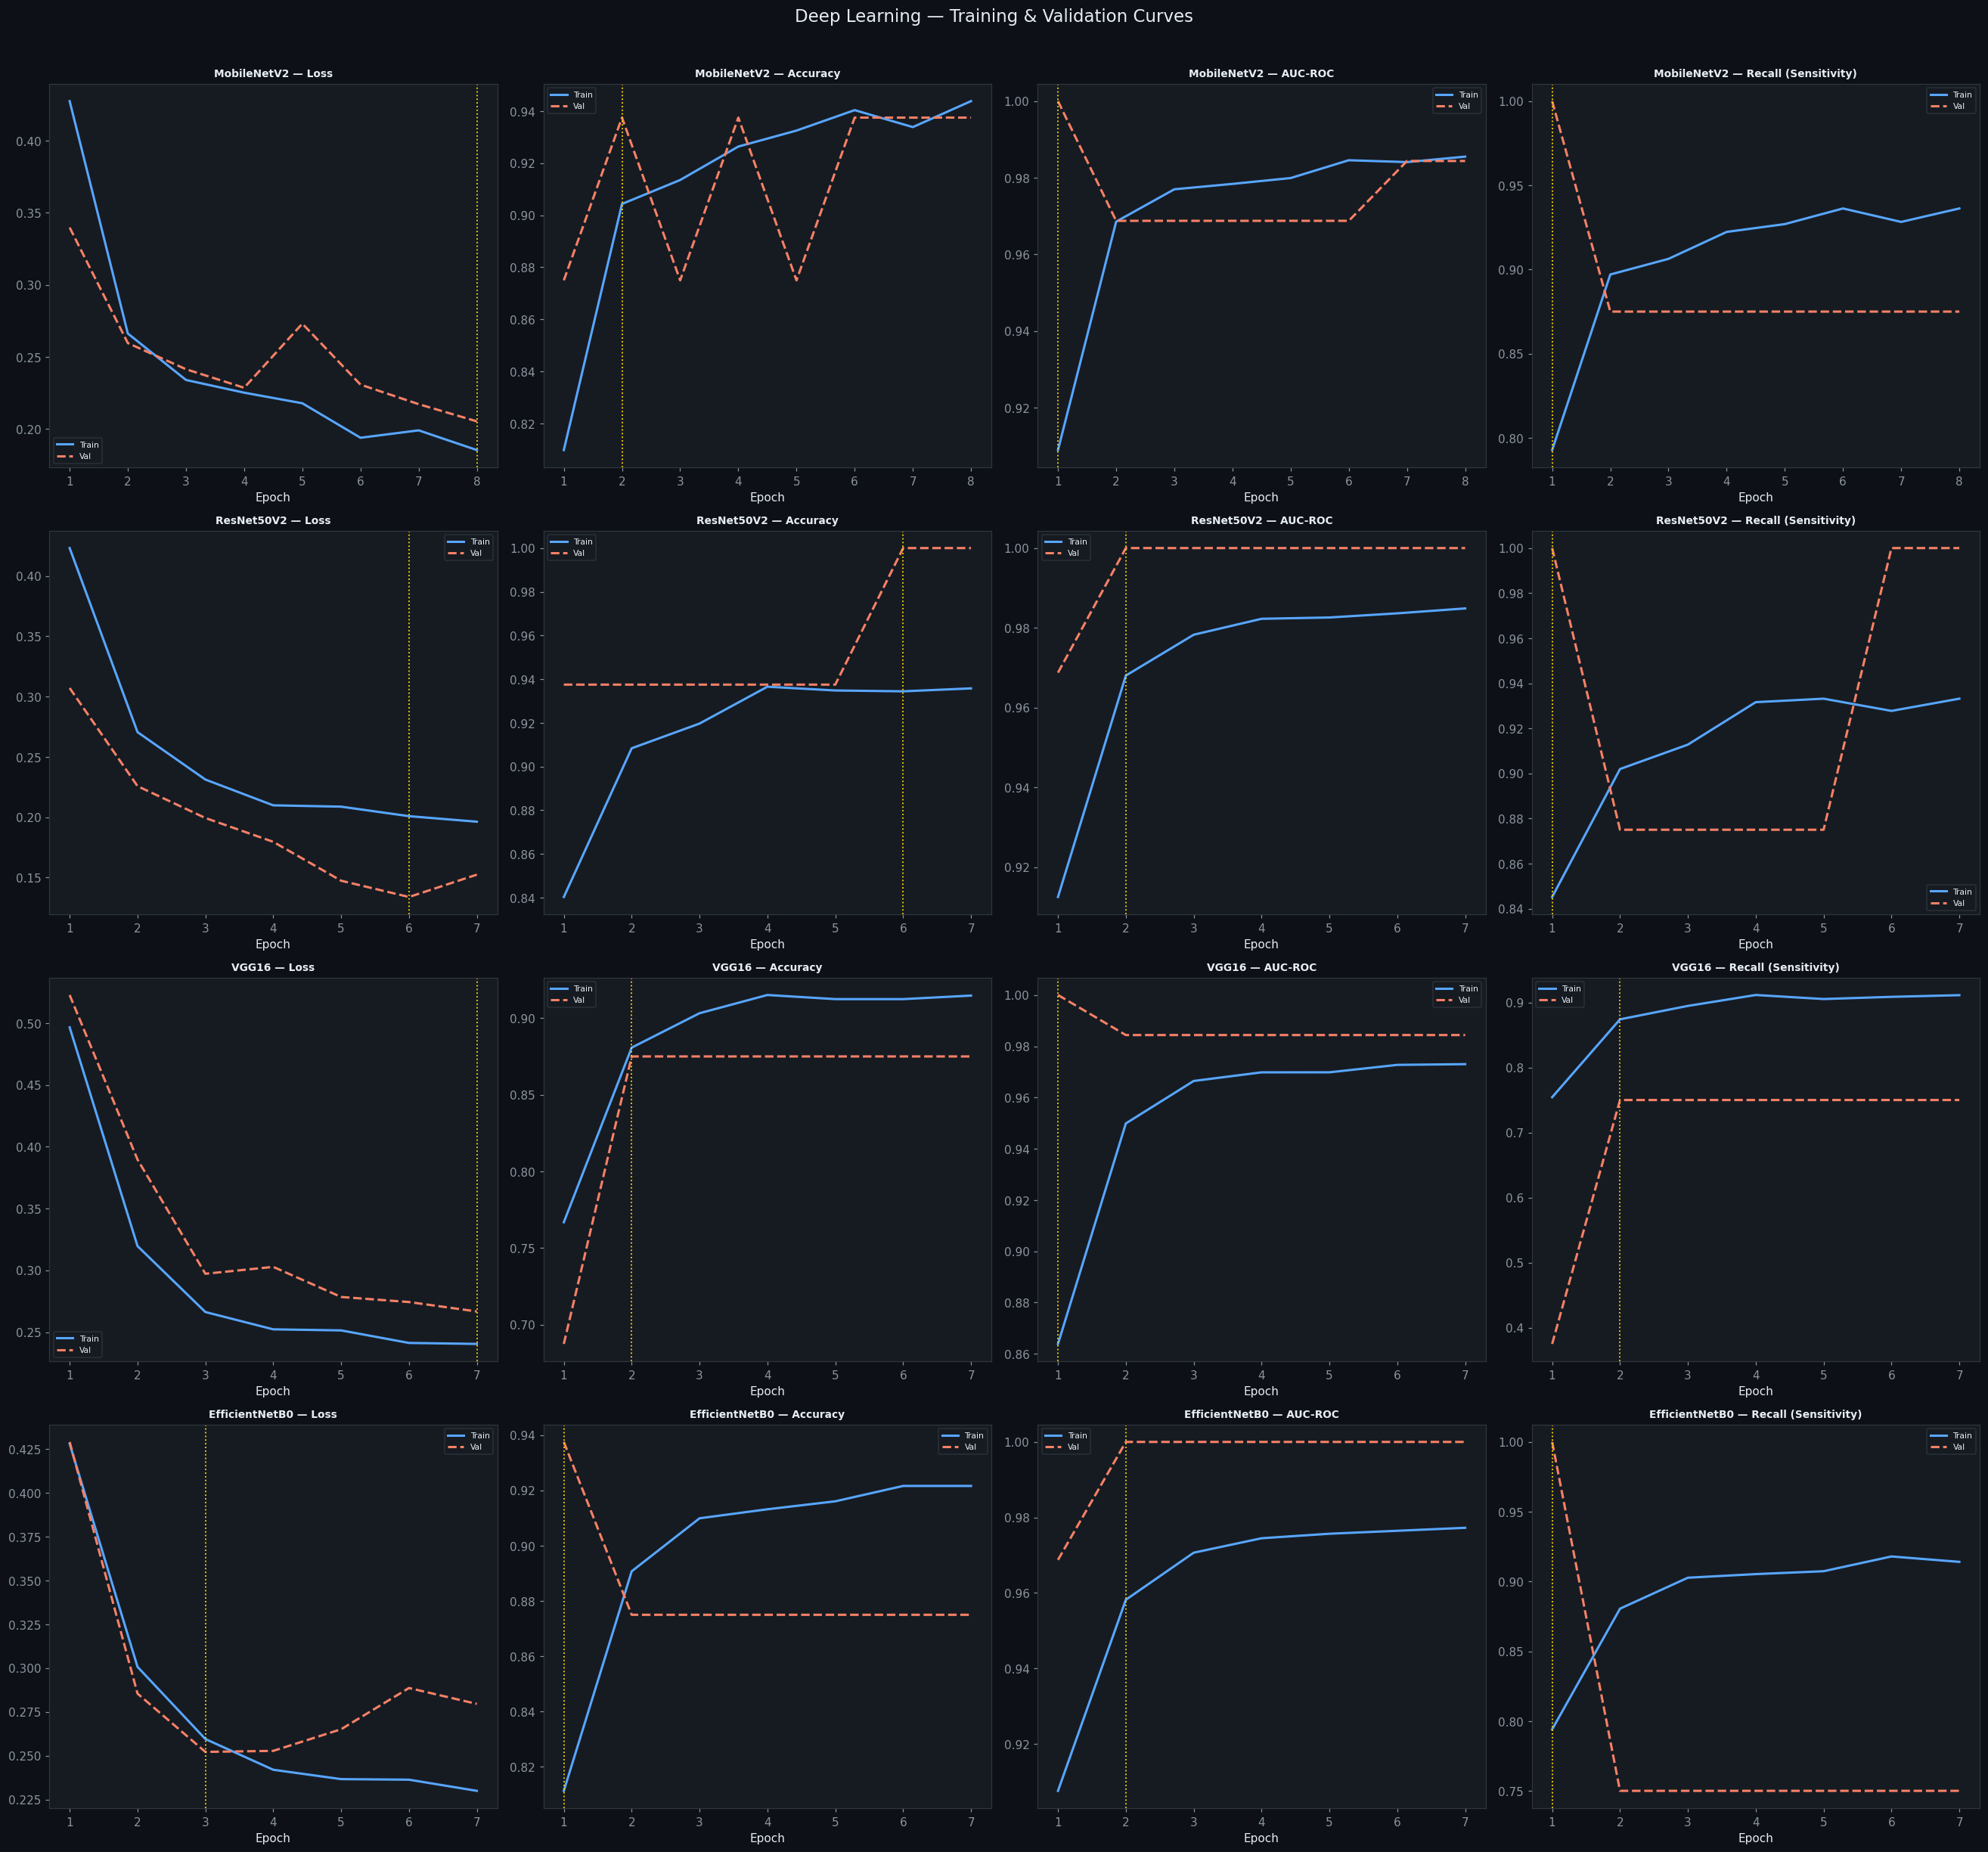

In [ ]:
#  Training & Validation Curves (all 4 DL models)
metric_pairs = [
    ("loss",     "val_loss",     "Loss"),
    ("accuracy", "val_accuracy", "Accuracy"),
    ("auc",      "val_auc",      "AUC-ROC"),
    ("recall",   "val_recall",   "Recall (Sensitivity)"),
]
fig, axes = plt.subplots(len(DL_CONFIGS), 4, figsize=(24, 5.5*len(DL_CONFIGS)))
fig.suptitle("Deep Learning — Training & Validation Curves", fontsize=15, y=1.01)

for row, (mname, hist) in enumerate(DL_HISTORIES.items()):
    for col, (tk, vk, lbl) in enumerate(metric_pairs):
        ax  = axes[row, col]
        tv  = hist.get(tk, []);  vv = hist.get(vk, [])
        ep  = range(1, len(tv)+1)
        ax.plot(ep, tv, color=PAL[0], lw=2, label="Train")
        ax.plot(ep, vv, color=PAL[1], lw=2, linestyle="--", label="Val")
        ax.set_title(f"{mname} — {lbl}", fontsize=9)
        ax.set_xlabel("Epoch"); ax.legend(fontsize=7)
        best = int(np.argmin(vv)) if tk=="loss" else int(np.argmax(vv))
        ax.axvline(best+1, color="#ffd700", lw=1.2, linestyle=":")
plt.tight_layout()
plt.savefig("dl_training_curves.png", dpi=120, bbox_inches="tight", facecolor=BG)
plt.show()

#  ROC CURVES FOR DEEP LEARNING MODELS

ROC curves are generated for the deep-learning models. AUC summarizes the model's ability to distinguish between the two classes across classification thresholds.


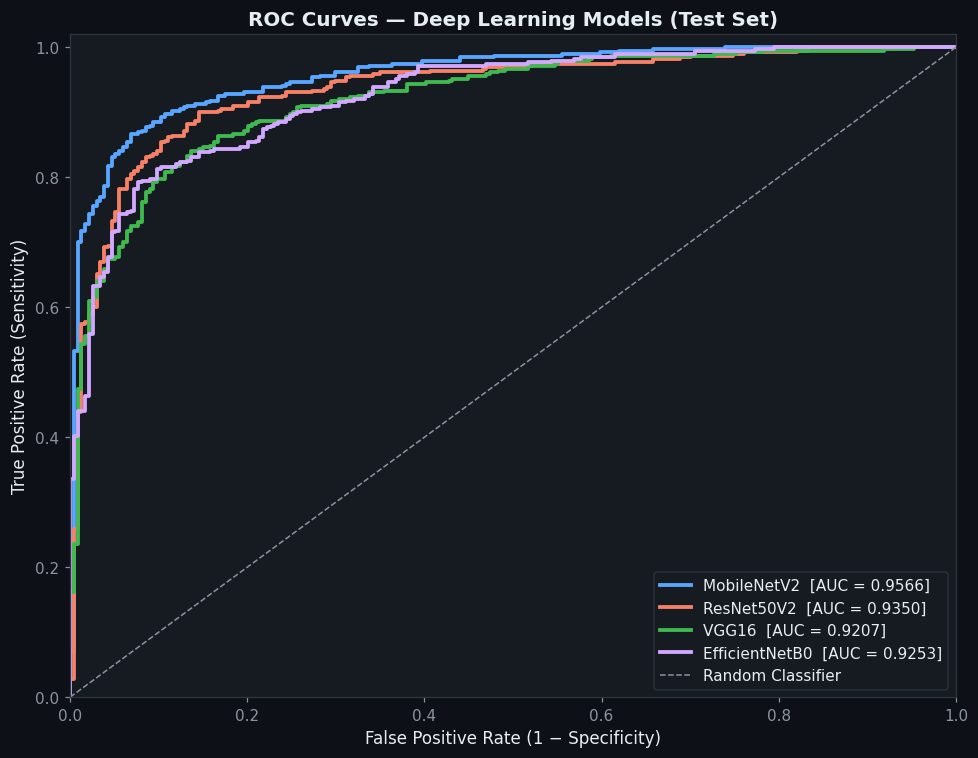

In [ ]:
# ROC Curves — DL models (test set)
fig, ax = plt.subplots(figsize=(9, 7))
ax.set_title("ROC Curves — Deep Learning Models (Test Set)", fontsize=13)
for i, (name, res) in enumerate(DL_RESULTS.items()):
    fpr, tpr, _ = roc_curve(res["y_true"], res["y_prob"])
    ax.plot(fpr, tpr, color=PAL[i], lw=2.5,label=f"{name}  [AUC = {res['auc']:.4f}]")
ax.plot([0,1],[0,1], color=MUTED, lw=1, linestyle="--", label="Random Classifier")
ax.set_xlabel("False Positive Rate (1 − Specificity)", fontsize=11)
ax.set_ylabel("True Positive Rate (Sensitivity)", fontsize=11)
ax.legend(fontsize=10, loc="lower right")
ax.set_xlim([0,1]); ax.set_ylim([0, 1.02])
plt.tight_layout()
plt.savefig("dl_roc_curves.png", dpi=120, bbox_inches="tight", facecolor=BG)
plt.show()

# DEEP LEARNING MODEL COMPARISON

The deep-learning models are compared using the evaluation metrics calculated on the test set.


In [ ]:
# DL Comparison Table
dl_cmp = pd.DataFrame({
    name: {
        "Accuracy":    f"{r['accuracy']:.4f}",
        "AUC-ROC":     f"{r['auc']:.4f}",
        "F1-Score":    f"{r['f1']:.4f}",
        "Recall":      f"{r['recall']:.4f}",
        "Precision":   f"{r['precision']:.4f}",
        "Balanced Acc":f"{r['bal_acc']:.4f}",
        "MCC":         f"{r['mcc']:.4f}",
        "Train Time(s)":f"{r['train_time']:.0f}",
    } for name, r in DL_RESULTS.items()
}).T

print("Deep Learning Model Comparison Table (Test Set)")
print("=" * 70)
display(dl_cmp)

best_dl = max(DL_RESULTS, key=lambda k: DL_RESULTS[k]["auc"])
print(f"\n Best DL Backbone (AUC-ROC): {best_dl} "f"(AUC = {DL_RESULTS[best_dl]['auc']:.4f})")

Deep Learning Model Comparison Table (Test Set)


,Accuracy,AUC-ROC,F1-Score,Recall,Precision,Balanced Acc,MCC,Train Time(s)
MobileNetV2,0.8494,0.9566,0.8897,0.9718,0.8203,0.8085,0.6814,2470
ResNet50V2,0.8654,0.9350,0.8871,0.8462,0.9322,0.8718,0.7266,4281
VGG16,0.7708,0.9207,0.7817,0.6564,0.9660,0.8090,0.6052,14832
EfficientNetB0,0.8333,0.9253,0.8729,0.9154,0.8341,0.8060,0.6383,2160



 Best DL Backbone (AUC-ROC): MobileNetV2 (AUC = 0.9566)


#  FINE-TUNING THE BEST DEEP LEARNING MODEL

The best base deep-learning model according to the notebook's AUC criterion is fine-tuned. Additional pretrained backbone layers are unfrozen and trained with a smaller learning rate.


Fine-tuning: MobileNetV2_FT  (Phase-1 AUC = 0.9566)
  Trainable layers after unfreeze : 9
  Fine-tune LR                    : 1e-05
Found 5216 validated image filenames belonging to 2 classes.
Found 16 validated image filenames belonging to 2 classes.
Found 624 validated image filenames belonging to 2 classes.
Epoch 1/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 290s 2s/step - accuracy: 0.8637 - auc: 0.9300 - loss: 0.3826 - recall: 0.8738 - val_accuracy: 0.7500 - val_auc: 0.9766 - val_loss: 0.7386 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 2/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 263s 2s/step - accuracy: 0.8976 - auc: 0.9666 - loss: 0.2772 - recall: 0.8883 - val_accuracy: 0.6250 - val_auc: 0.9688 - val_loss: 0.9434 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 3/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9079 - auc: 0.9720 - loss: 0.2576 - recall: 0.8961
Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
163/163 ━━━━━━━━━━━━━━━━━━━━ 264s 2s/step 

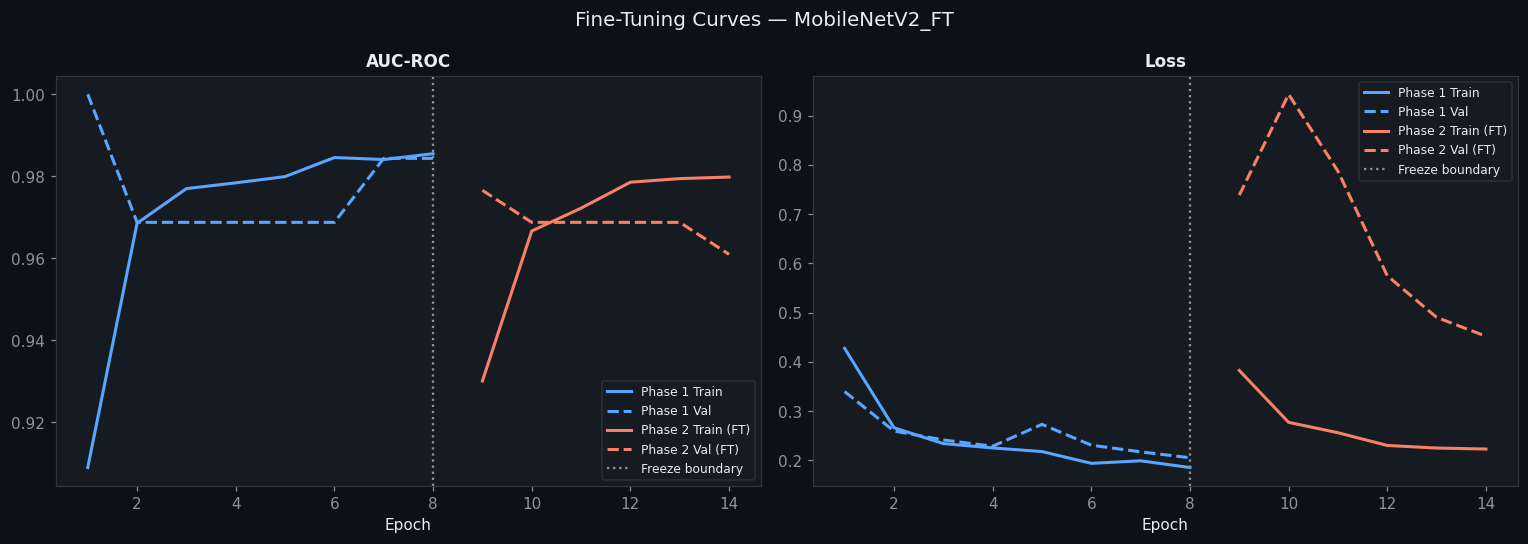

 Fine-tuned model saved → models/MobileNetV2_FT.keras


In [ ]:
FINETUNE_LR        = 1e-5
FINETUNE_EPOCHS    = 15
FINETUNE_UNFREEZE  = 30

# Identify the best performing base (non-fine-tuned) model
# We filter DL_RESULTS to only include models without the '_FT' suffix
base_models_for_finetuning = {k: v for k, v in DL_RESULTS.items() if not k.endswith('_FT')}
if not base_models_for_finetuning:
    print("Error: No base deep learning models found in DL_RESULTS to fine-tune.")
    # Depending on context, you might want to raise an error or exit here.
    # For this flow, we assume ukxDhXD2yflI has run and populated base models.

BEST_BASE_DL_NAME = max(base_models_for_finetuning, key=lambda k: base_models_for_finetuning[k]["auc"])
FINE_TUNED_MODEL_KEY = f"{BEST_BASE_DL_NAME}_FT" # e.g., 'MobileNetV2_FT'

print(f"Fine-tuning: {FINE_TUNED_MODEL_KEY}  (Phase-1 AUC = {DL_RESULTS[BEST_BASE_DL_NAME]['auc']:.4f})")

# Load the best *base* model for fine-tuning
best_model_ft = keras.models.load_model(f"models/{BEST_BASE_DL_NAME}.keras")

backbone_layer = best_model_ft.layers[1]
backbone_layer.trainable = True
for layer in backbone_layer.layers[:-FINETUNE_UNFREEZE]:
    layer.trainable = False
best_model_ft.compile(
    optimizer=optimizers.Adam(FINETUNE_LR),
    loss="binary_crossentropy",
    metrics=["accuracy",
             keras.metrics.AUC(name="auc"),
             keras.metrics.Recall(name="recall")]
)

trainable_count = sum(1 for l in best_model_ft.layers if l.trainable)
print(f"  Trainable layers after unfreeze : {trainable_count}")
print(f"  Fine-tune LR                    : {FINETUNE_LR}")

ft_callbacks = [
    EarlyStopping(monitor="val_auc", patience=5,
                  restore_best_weights=True, mode="max", verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                      patience=2, min_lr=1e-8, verbose=1),
    ModelCheckpoint(f"models/{FINE_TUNED_MODEL_KEY}.keras", # Save with the consistent fine-tuned key
                    monitor="val_auc", save_best_only=True, mode="max"),
]

# Use the pre-processing function for the BEST_BASE_DL_NAME model
tg_ft, vg_ft, testg_ft = make_generators(DL_CONFIGS[BEST_BASE_DL_NAME][1])

t0_ft  = time.time()
ft_hist = best_model_ft.fit(
    tg_ft, validation_data=vg_ft, epochs=FINETUNE_EPOCHS,
    callbacks=ft_callbacks, class_weight=CLASS_WEIGHTS, verbose=1
)
elapsed_ft = time.time() - t0_ft
# Evaluate the fine-tuned model on test set
testg_ft.reset()
y_prob_ft = best_model_ft.predict(testg_ft, verbose=0).flatten()
y_true_ft = testg_ft.classes
y_pred_ft = (y_prob_ft >= 0.5).astype(int)

tn_ft, fp_ft, fn_ft, tp_ft = confusion_matrix(y_true_ft, y_pred_ft).ravel()

FT_RESULT = {
    "accuracy":    accuracy_score(y_true_ft, y_pred_ft),
    "auc":         roc_auc_score(y_true_ft, y_prob_ft),
    "f1":          f1_score(y_true_ft, y_pred_ft),
    "recall":      recall_score(y_true_ft, y_pred_ft),
    "specificity": tn_ft / (tn_ft + fp_ft),
    "precision":   precision_score(y_true_ft, y_pred_ft),
    "mcc":         matthews_corrcoef(y_true_ft, y_pred_ft),
    "bal_acc":     balanced_accuracy_score(y_true_ft, y_pred_ft),
    "y_true": y_true_ft, "y_prob": y_prob_ft, "y_pred": y_pred_ft,
}

print(f"\n{'═'*55}")
print(f"  Phase 1  (frozen)     AUC = {DL_RESULTS[BEST_BASE_DL_NAME]['auc']:.4f}  "
      f"Recall = {DL_RESULTS[BEST_BASE_DL_NAME]['recall']:.4f}")
print(f"  Phase 2  (fine-tuned) AUC = {FT_RESULT['auc']:.4f}  "
      f"Recall = {FT_RESULT['recall']:.4f}")
delta = FT_RESULT['auc'] - DL_RESULTS[BEST_BASE_DL_NAME]['auc']
print(f"  AUC from fine-tuning: {delta:+.4f}  "
      f"({'improvement ' if delta >= 0 else ' Phase 1 already optimal'})")
print(f"{'═'*55}")

# Plot: Phase 1 vs Phase 2 training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f"Fine-Tuning Curves — {FINE_TUNED_MODEL_KEY}", fontsize=13)
for ax, (metric, label) in zip(axes, [("auc", "AUC-ROC"), ("loss", "Loss")]):
    # Ensure to get history from the original best model for Phase 1
    p1_train = DL_HISTORIES[BEST_BASE_DL_NAME].get(metric, [])
    p1_val   = DL_HISTORIES[BEST_BASE_DL_NAME].get(f"val_{metric}", [])
    p2_train = ft_hist.history.get(metric, [])
    p2_val   = ft_hist.history.get(f"val_{metric}", [])

    ep1 = range(1, len(p1_train) + 1)
    ep2 = range(len(p1_train) + 1, len(p1_train) + len(p2_train) + 1)

    ax.plot(ep1, p1_train, color=PAL[0], lw=2, label="Phase 1 Train")
    ax.plot(ep1, p1_val,   color=PAL[0], lw=2, linestyle="--", label="Phase 1 Val")
    ax.plot(ep2, p2_train, color=PAL[1], lw=2, label="Phase 2 Train (FT)")
    ax.plot(ep2, p2_val,   color=PAL[1], lw=2, linestyle="--", label="Phase 2 Val (FT)")
    ax.axvline(len(p1_train), color=MUTED, lw=1.5, linestyle=":", label="Freeze boundary")
    ax.set_title(f"{label}"); ax.set_xlabel("Epoch"); ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("figures/finetuning_curves.png", dpi=120, bbox_inches="tight", facecolor=BG)
plt.show()

# Adding the  fine-tuned model to DL_RESULTS for comparison
DL_RESULTS[FINE_TUNED_MODEL_KEY] = FT_RESULT
DL_RESULTS[FINE_TUNED_MODEL_KEY]["train_time"] = elapsed_ft
print(f" Fine-tuned model saved → models/{FINE_TUNED_MODEL_KEY}.keras")

#  CNN FEATURE EXTRACTION

The selected CNN backbone is used as a fixed feature extractor. High-level image representations are generated and prepared for downstream classical machine-learning models.


In [ ]:
BEST_DL_NAME_FULL = max(DL_RESULTS, key=lambda k: DL_RESULTS[k]["auc"])
base_model_key = BEST_DL_NAME_FULL.replace("_FT", "")
BEST_BASE_FN, BEST_PREP_FN = DL_CONFIGS[base_model_key]
print(f"Feature Extractor : {BEST_DL_NAME_FULL}")
print(f"  Test AUC-ROC    : {DL_RESULTS[BEST_DL_NAME_FULL]['auc']:.4f}")
base = BEST_BASE_FN(include_top=False, weights="imagenet", input_shape=IMG_SHAPE)
gap  = layers.GlobalAveragePooling2D()(base.output)
FEAT_EXTRACTOR = keras.Model(inputs=base.input, outputs=gap,
                              name=f"{BEST_DL_NAME_FULL}_features")
FEAT_EXTRACTOR.trainable = False
print(f"  Feature vector dim: {FEAT_EXTRACTOR.output_shape[1]}")
def extract_features(df, desc=""):
    gen  = ImageDataGenerator(preprocessing_function=BEST_PREP_FN)
    flow = gen.flow_from_dataframe(
        df, x_col="filepath", y_col="label",
        target_size=IMG_SIZE, batch_size=64,
        class_mode="binary", shuffle=False)
    print(f"  Extracting {desc} ({len(df)} images)...")
    return FEAT_EXTRACTOR.predict(flow, verbose=1), flow.classes
X_tr, y_tr = extract_features(df_train, "Train")
X_vl, y_vl = extract_features(df_val,   "Val")
X_te, y_te = extract_features(df_test,  "Test")
X_ml = np.vstack([X_tr, X_vl])
y_ml = np.concatenate([y_tr, y_vl])

print(f"\nX_ml (train+val) : {X_ml.shape}")
print(f"X_test           : {X_te.shape}")
print(f"Class balance    : {(y_ml==0).sum()} NORMAL / {(y_ml==1).sum()} PNEUMONIA")

Feature Extractor : MobileNetV2
  Test AUC-ROC    : 0.9566
  Feature vector dim: 1280
Found 5216 validated image filenames belonging to 2 classes.
  Extracting Train (5218 images)...
82/82 ━━━━━━━━━━━━━━━━━━━━ 189s 2s/step
Found 16 validated image filenames belonging to 2 classes.
  Extracting Val (18 images)...
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 563ms/step
Found 624 validated image filenames belonging to 2 classes.
  Extracting Test (624 images)...
10/10 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step

X_ml (train+val) : (5232, 1280)
X_test           : (624, 1280)
Class balance    : 1349 NORMAL / 3883 PNEUMONIA


# PCA DIMENSIONALITY REDUCTION

Standardization and Principal Component Analysis (PCA) are applied to the extracted CNN features. PCA reduces dimensionality while retaining the configured proportion of variance.


In [ ]:
scaler    = StandardScaler()
X_ml_sc   = scaler.fit_transform(X_ml)
X_te_sc   = scaler.transform(X_te)
pca       = PCA(n_components=PCA_VARIANCE, random_state=SEED, svd_solver="full")
X_ml_pca  = pca.fit_transform(X_ml_sc)
X_te_pca  = pca.transform(X_te_sc)
N_PC      = pca.n_components_
print(f"PCA Summary:")
print(f"  Original dims : {X_ml_sc.shape[1]}")
print(f"  PCA components: {N_PC}  (retaining {PCA_VARIANCE*100:.0f}% variance)")
print(f"  Compression   : {X_ml_sc.shape[1]/N_PC:.1f}× reduction")

PCA Summary:
  Original dims : 1280
  PCA components: 741  (retaining 95% variance)
  Compression   : 1.7× reduction


# FEATURE-SPACE VISUALIZATION

The reduced feature representation is visualized to inspect how the two classes are distributed in feature space.


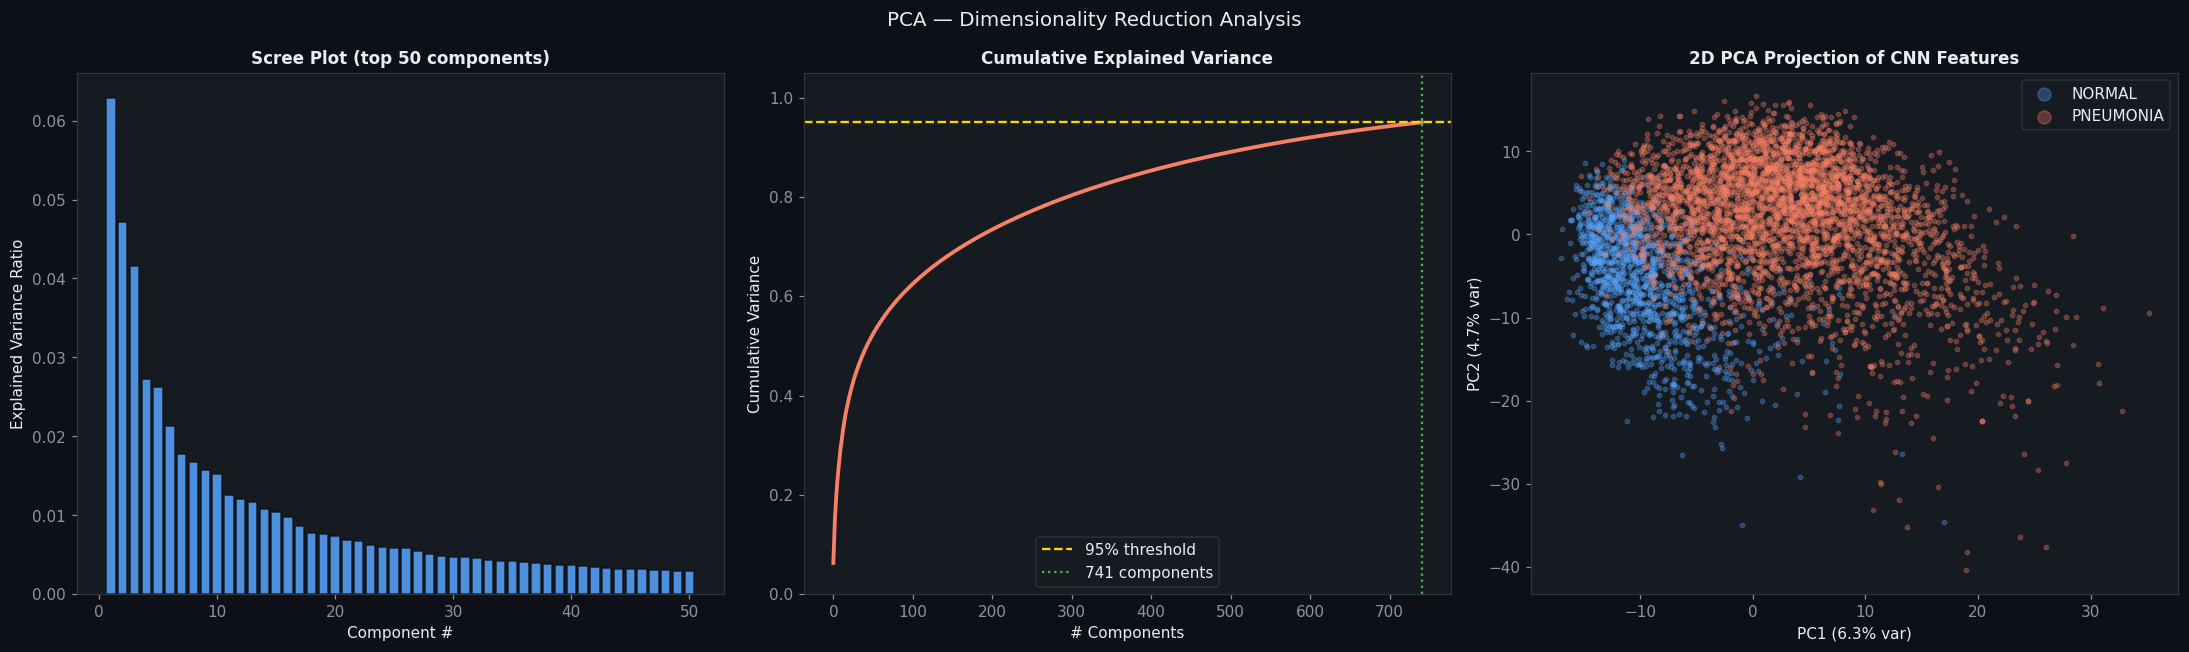

Classes occupy separable regions in PCA space — ML classifiers can exploit this.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("PCA — Dimensionality Reduction Analysis", fontsize=13)
# Scree plot
evr    = pca.explained_variance_ratio_
show_n = min(50, len(evr))
axes[0].bar(range(1, show_n+1), evr[:show_n], color=PAL[0], alpha=0.85, edgecolor=BG)
axes[0].set_title(f"Scree Plot (top {show_n} components)")
axes[0].set_xlabel("Component #"); axes[0].set_ylabel("Explained Variance Ratio")
# Cumulative variance
cumv = np.cumsum(evr)
axes[1].plot(cumv, color=PAL[1], lw=2.5)
axes[1].axhline(PCA_VARIANCE, color="#ffd700", lw=1.5, linestyle="--",
                label=f"{PCA_VARIANCE*100:.0f}% threshold")
axes[1].axvline(N_PC, color="#3fb950", lw=1.5, linestyle=":",
                label=f"{N_PC} components")
axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("# Components"); axes[1].set_ylabel("Cumulative Variance")
axes[1].legend(); axes[1].set_ylim([0, 1.05])
# 2D scatter
pca2d = PCA(n_components=2, random_state=SEED)
X2d   = pca2d.fit_transform(X_ml_sc)
for i, label in enumerate(CLASSES):
    mask = y_ml == i
    axes[2].scatter(X2d[mask,0], X2d[mask,1],
                    color=PAL[i], alpha=0.30, s=8, label=label)
axes[2].set_title("2D PCA Projection of CNN Features")
axes[2].set_xlabel(f"PC1 ({pca2d.explained_variance_ratio_[0]*100:.1f}% var)")
axes[2].set_ylabel(f"PC2 ({pca2d.explained_variance_ratio_[1]*100:.1f}% var)")
axes[2].legend(markerscale=3)
plt.tight_layout()
plt.savefig("pca_analysis.png", dpi=120, bbox_inches="tight", facecolor=BG)
plt.show()
print("Classes occupy separable regions in PCA space — ML classifiers can exploit this.")

#  UMAP VS PCA VISUALIZATION

UMAP provides a nonlinear two-dimensional visualization of the feature space. In this notebook, UMAP is used for visualization, while PCA features are used for machine-learning training.


Computing UMAP projection (visualisation only)...


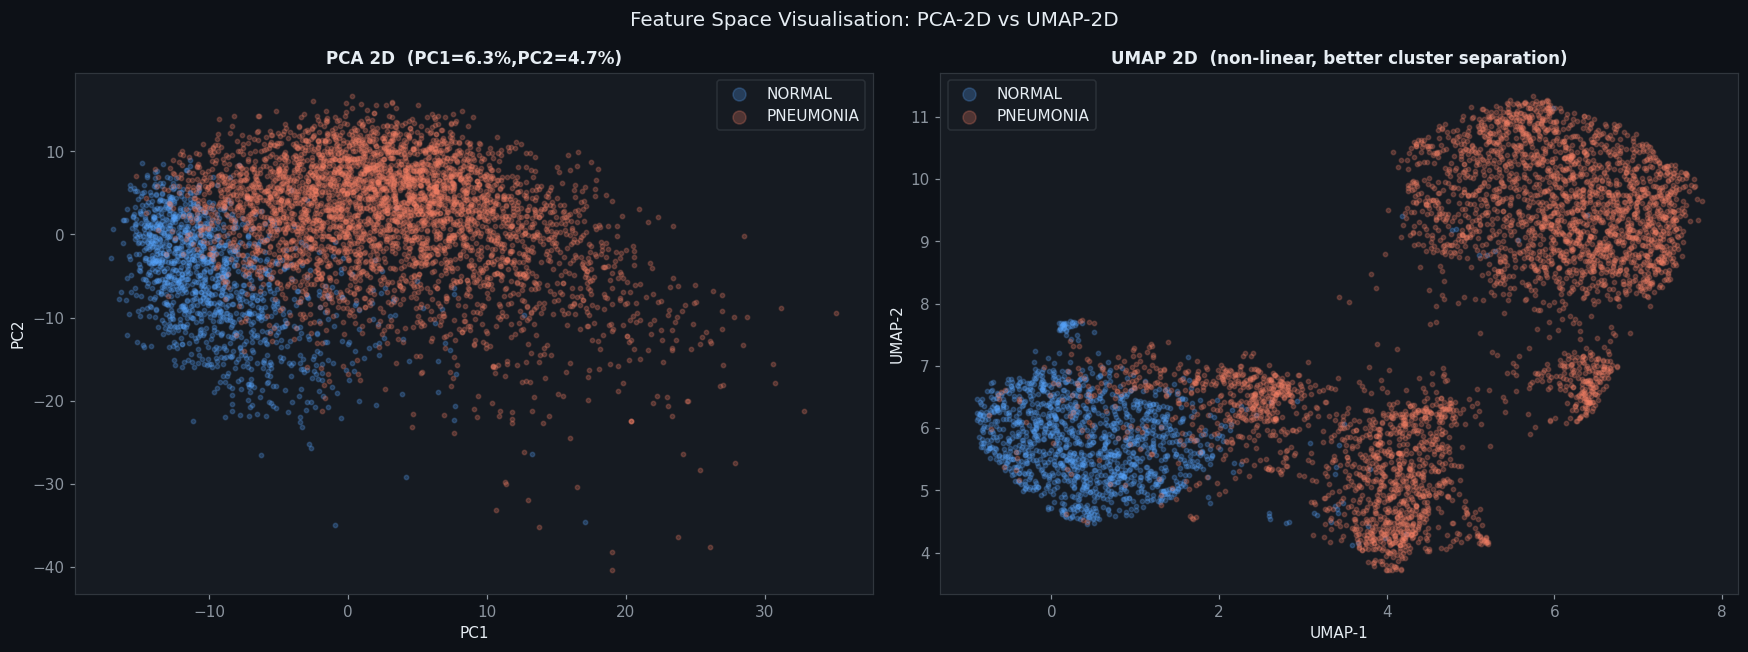

UMAP is used for visualisation only. PCA is used for ML training.
 UMAP typically shows tighter, better-separated clusters for CNN features.


In [ ]:
try:
    import umap
    print("Computing UMAP projection (visualisation only)...")
    reducer   = umap.UMAP(n_components=2, random_state=SEED, n_neighbors=30,
                           min_dist=0.1, metric="euclidean")
    X_umap_2d = reducer.fit_transform(X_ml_sc)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle("Feature Space Visualisation: PCA-2D vs UMAP-2D", fontsize=13)
    pca2d_vis = PCA(n_components=2, random_state=SEED)
    X_pca_2d  = pca2d_vis.fit_transform(X_ml_sc)
    for i, label in enumerate(CLASSES):
        mask = y_ml == i
        axes[0].scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1],color=PAL[i], alpha=0.25, s=8, label=label)
    axes[0].set_title(f"PCA 2D  (PC1={pca2d_vis.explained_variance_ratio_[0]*100:.1f}%,"f"PC2={pca2d_vis.explained_variance_ratio_[1]*100:.1f}%)")
    axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].legend(markerscale=3)
    for i, label in enumerate(CLASSES):
        mask = y_ml == i
        axes[1].scatter(X_umap_2d[mask, 0], X_umap_2d[mask, 1],color=PAL[i], alpha=0.25, s=8, label=label)
    axes[1].set_title("UMAP 2D  (non-linear, better cluster separation)")
    axes[1].set_xlabel("UMAP-1"); axes[1].set_ylabel("UMAP-2"); axes[1].legend(markerscale=3)
    plt.tight_layout()
    plt.savefig("figures/umap_vs_pca.png", dpi=120, bbox_inches="tight", facecolor=BG)
    plt.show()
    print("UMAP is used for visualisation only. PCA is used for ML training.")
    print(" UMAP typically shows tighter, better-separated clusters for CNN features.")

except ImportError:
    print("umap-learn not installed. Run: !pip install umap-learn -q")

#  CLASSICAL MACHINE-LEARNING SETUP

This section prepares the classical machine-learning classifiers that operate on the extracted and PCA-reduced CNN features.


In [ ]:
n_pos = (y_ml == 1).sum()
n_neg = (y_ml == 0).sum()
ML_MODELS = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, C=1.0, class_weight="balanced",
        solver="lbfgs", random_state=SEED),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=12, min_samples_split=10,
        class_weight="balanced", random_state=SEED),

    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=20, min_samples_split=5,
        class_weight="balanced", n_jobs=-1, random_state=SEED),

    "SVM": SVC(
        kernel="rbf", C=10.0, gamma="scale", probability=True,
        class_weight="balanced", random_state=SEED),

    "KNN": KNeighborsClassifier(
        n_neighbors=7, weights="distance", n_jobs=-1),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=300, learning_rate=0.08, max_depth=5,
        subsample=0.8, random_state=SEED),

    "XGBoost": XGBClassifier(
        n_estimators=400, learning_rate=0.08, max_depth=6,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=n_neg/n_pos,
        eval_metric="logloss", use_label_encoder=False,
        n_jobs=-1, random_state=SEED),

    "LightGBM": LGBMClassifier(
        n_estimators=400, learning_rate=0.08, max_depth=6,
        num_leaves=50, subsample=0.8, class_weight="balanced",
        n_jobs=-1, verbose=-1, random_state=SEED),
}
print(f" {len(ML_MODELS)} models defined on {N_PC}-dim PCA features.")

 8 models defined on 741-dim PCA features.


#  CLASSICAL MACHINE-LEARNING TRAINING

The configured classical ML models are trained using the PCA features and evaluated on the test set. Metrics include accuracy, AUC, F1-score, recall, specificity, precision, MCC, and training time.


In [ ]:
ML_RESULTS = {}
print(f"{'Model':<22} {'Acc':>7} {'AUC':>7} {'F1':>7} "
      f"{'Recall':>8} {'Spec':>8} {'Prec':>7} {'MCC':>7} {'Time':>6}")
print("─" * 84)
for name, clf in ML_MODELS.items():
    t0  = time.time()
    clf.fit(X_ml_pca, y_ml)
    elapsed = time.time() - t0

    y_prob = clf.predict_proba(X_te_pca)[:, 1]
    y_pred = clf.predict(X_te_pca)
    tn, fp, fn, tp = confusion_matrix(y_te, y_pred).ravel()
    ML_RESULTS[name] = {
        "accuracy":    accuracy_score(y_te, y_pred),
        "auc":         roc_auc_score(y_te, y_prob),
        "f1":          f1_score(y_te, y_pred),
        "recall":      recall_score(y_te, y_pred),
        "specificity": tn / (tn + fp),
        "precision":   precision_score(y_te, y_pred),
        "mcc":         matthews_corrcoef(y_te, y_pred),
        "bal_acc":     balanced_accuracy_score(y_te, y_pred),
        "y_pred":      y_pred, "y_prob": y_prob, "time": elapsed,
    }
    r = ML_RESULTS[name]
    print(f"{name:<22} {r['accuracy']:>7.4f} {r['auc']:>7.4f} {r['f1']:>7.4f} "
          f"{r['recall']:>8.4f} {r['specificity']:>8.4f} {r['precision']:>7.4f} "
          f"{r['mcc']:>7.4f} {elapsed:>5.1f}s")

print("\n All 8 ML models trained and evaluated.")

Model                      Acc     AUC      F1   Recall     Spec    Prec     MCC   Time
────────────────────────────────────────────────────────────────────────────────────
Logistic Regression     0.7933  0.9364  0.8575   0.9949   0.4573  0.7534  0.5765   0.6s
Decision Tree           0.7901  0.7363  0.8503   0.9538   0.5171  0.7670  0.5479   4.4s
Random Forest           0.6971  0.9274  0.8050   1.0000   0.1923  0.6736  0.3599  32.2s
SVM                     0.7997  0.9305  0.8616   0.9974   0.4701  0.7583  0.5919  18.6s
KNN                     0.8301  0.9302  0.8784   0.9821   0.5769  0.7946  0.6455   0.0s
Gradient Boosting       0.7949  0.9385  0.8568   0.9821   0.4829  0.7599  0.5711 618.1s
XGBoost                 0.8141  0.9420  0.8691   0.9872   0.5256  0.7762  0.6148  26.8s
LightGBM                0.8109  0.9452  0.8671   0.9872   0.5171  0.7731  0.6081  26.6s

 All 8 ML models trained and evaluated.


#  CROSS-VALIDATION

Five-fold cross-validation is used to examine the AUC behaviour of the classical machine-learning models across multiple training/validation splits.


In [ ]:
# 5-Fold Cross-Validation AUC
print("5-Fold Stratified CV AUC (train+val PCA features):")
print("-" * 55)
CV_SCORES = {}
skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
for name, clf in ML_MODELS.items():
    sc = cross_val_score(clf, X_ml_pca, y_ml, cv=skf,
                         scoring="roc_auc", n_jobs=-1)
    CV_SCORES[name] = sc
    print(f"  {name:<22}: {sc.mean():.4f} ± {sc.std():.4f}")

5-Fold Stratified CV AUC (train+val PCA features):
-------------------------------------------------------
  Logistic Regression   : 0.9958 ± 0.0011
  Decision Tree         : 0.8841 ± 0.0148
  Random Forest         : 0.9778 ± 0.0055
  SVM                   : 0.9974 ± 0.0008
  KNN                   : 0.9914 ± 0.0031
  Gradient Boosting     : 0.9916 ± 0.0017
  XGBoost               : 0.9940 ± 0.0017
  LightGBM              : 0.9934 ± 0.0016


# ROC CURVES FOR CLASSICAL ML MODELS

ROC curves are plotted for the classical ML models to compare their discrimination behaviour.


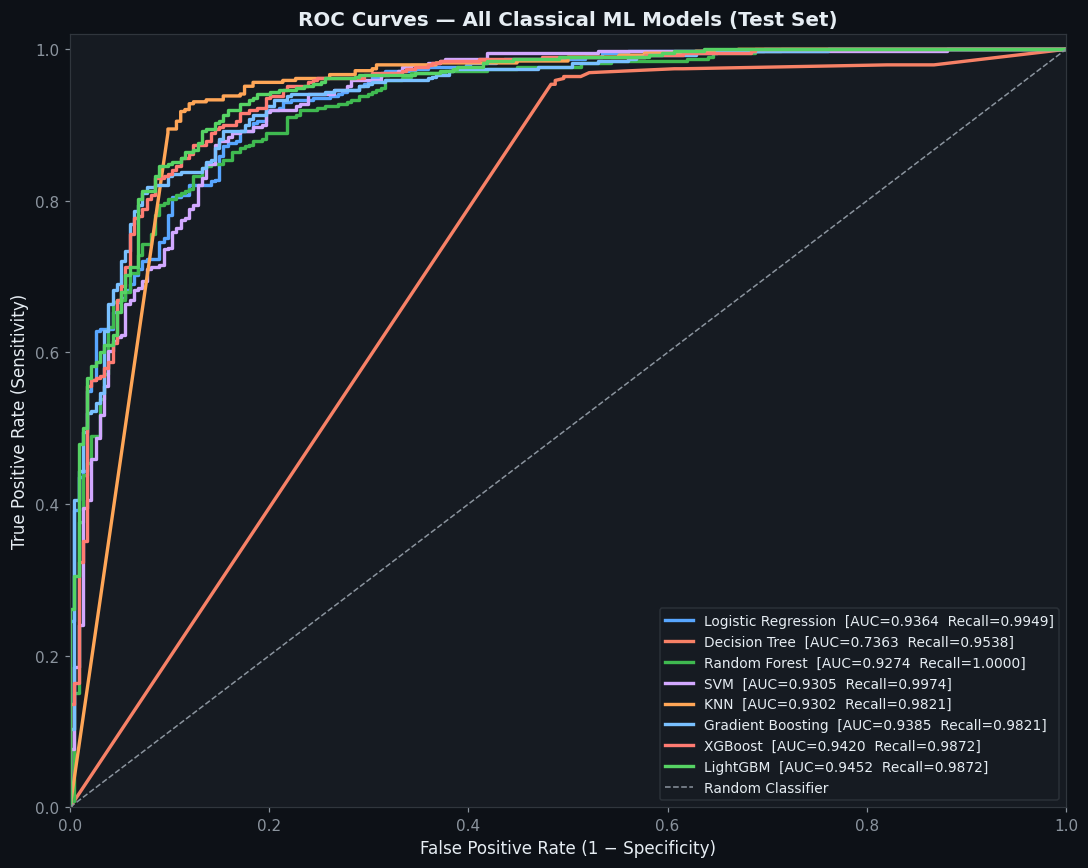

In [ ]:
# ROC Curves — ML models
fig, ax = plt.subplots(figsize=(10, 8))
ax.set_title("ROC Curves — All Classical ML Models (Test Set)", fontsize=13)

for i, (name, res) in enumerate(ML_RESULTS.items()):
    fpr, tpr, _ = roc_curve(y_te, res["y_prob"])
    ax.plot(fpr, tpr, color=PAL[i % len(PAL)], lw=2.2,
            label=f"{name}  [AUC={res['auc']:.4f}  Recall={res['recall']:.4f}]")

ax.plot([0, 1], [0, 1], color=MUTED, lw=1, linestyle="--", label="Random Classifier")
ax.set_xlabel("False Positive Rate (1 − Specificity)", fontsize=11)
ax.set_ylabel("True Positive Rate (Sensitivity)",fontsize=11)
ax.legend(fontsize=9, loc="lower right")
ax.set_xlim([0, 1]); ax.set_ylim([0, 1.02])
plt.tight_layout()
plt.savefig("figures/ml_roc_curves.png", dpi=120, bbox_inches="tight", facecolor=BG)
plt.show()

# CONFUSION MATRICES

Confusion matrices show true positives, true negatives, false positives, and false negatives for the classical models.


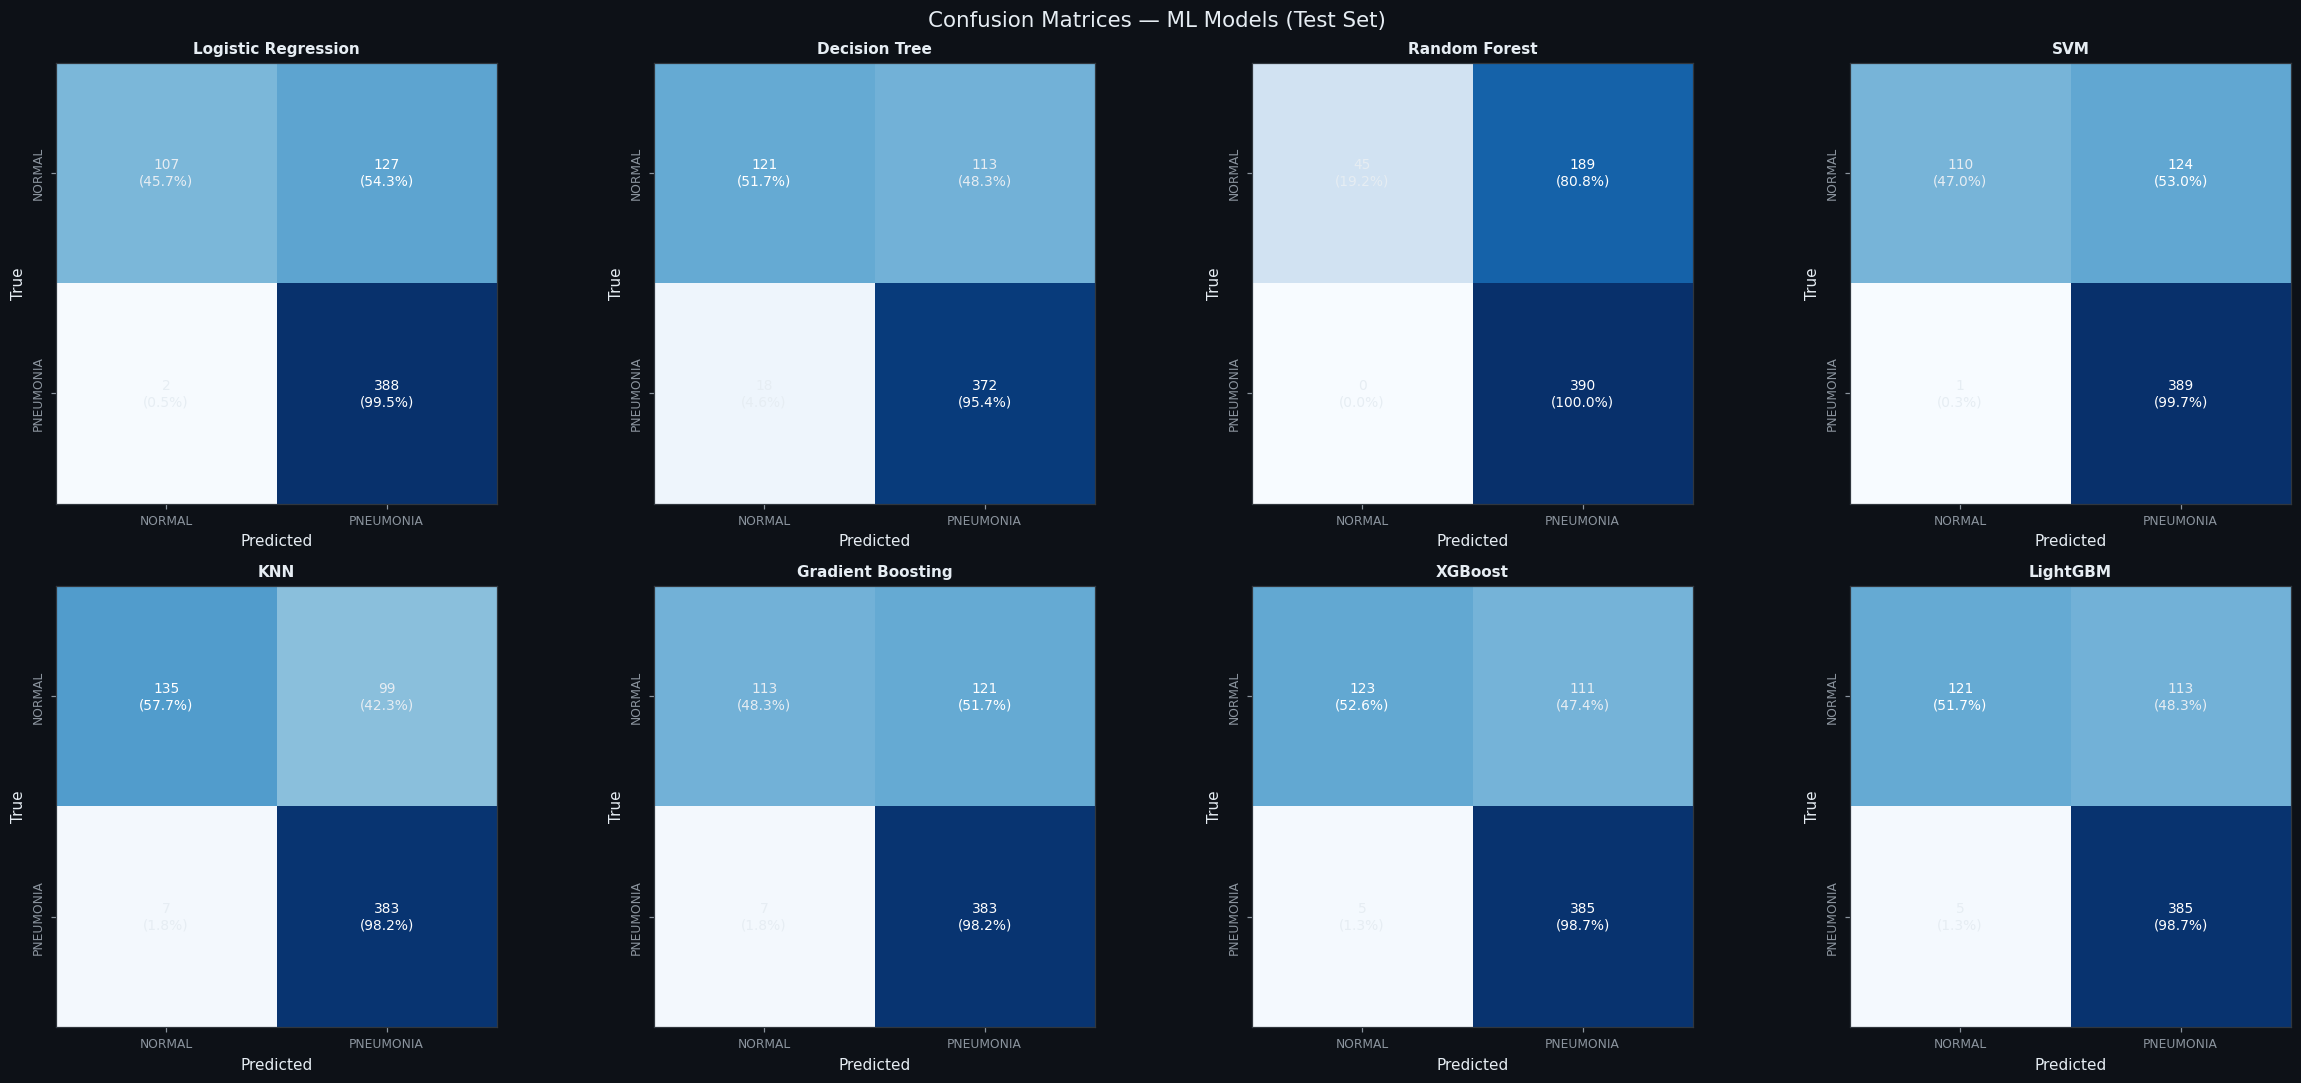

In [ ]:
# Confusion Matrices — 8 ML models
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
fig.suptitle("Confusion Matrices — ML Models (Test Set)", fontsize=14)
axes = axes.flatten()
for i, (name, res) in enumerate(ML_RESULTS.items()):
    cm   = confusion_matrix(y_te, res["y_pred"])
    cm_n = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
    axes[i].imshow(cm_n, cmap="Blues", vmin=0, vmax=1)
    axes[i].set_title(name, fontsize=10)
    axes[i].set_xticks([0,1]); axes[i].set_yticks([0,1])
    axes[i].set_xticklabels(CLASSES, fontsize=8)
    axes[i].set_yticklabels(CLASSES, fontsize=8, rotation=90, va="center")
    axes[i].set_xlabel("Predicted"); axes[i].set_ylabel("True")
    for r in range(2):
        for c in range(2):
            axes[i].text(c, r, f"{cm[r,c]}\n({cm_n[r,c]:.1%})",ha="center", va="center", fontsize=9,color="white" if cm_n[r,c]>0.5 else TXT)
plt.tight_layout()
plt.savefig("ml_confusion_matrices.png", dpi=120, bbox_inches="tight", facecolor=BG)
plt.show()

#  CROSS-VALIDATION COMPARISON

This visualization compares cross-validation AUC values between the classical machine-learning models.


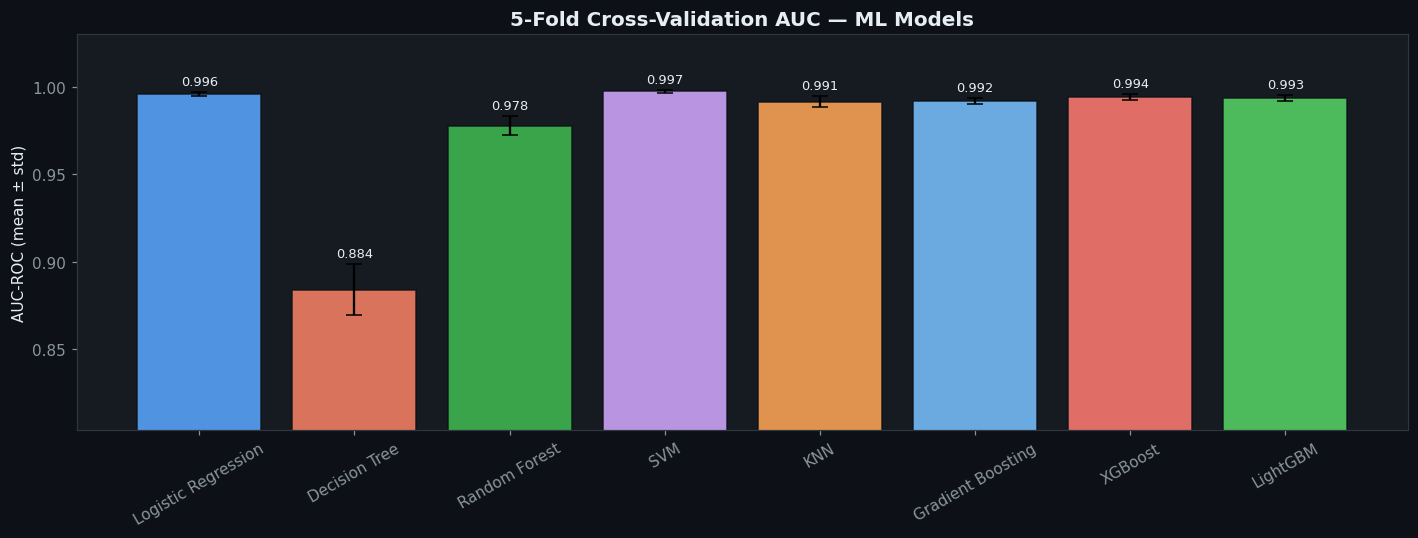

In [ ]:
# CV AUC bar chart
fig, ax = plt.subplots(figsize=(13, 5))
ax.set_title("5-Fold Cross-Validation AUC — ML Models", fontsize=13)
names_cv  = list(CV_SCORES.keys())
means_cv  = [CV_SCORES[n].mean() for n in names_cv]
stds_cv   = [CV_SCORES[n].std()  for n in names_cv]
bars = ax.bar(names_cv, means_cv, yerr=stds_cv, capsize=5,color=[PAL[i%len(PAL)] for i in range(len(names_cv))],alpha=0.87, edgecolor=BG)
ax.set_ylim([max(0.70, min(means_cv)-0.08), 1.03])
ax.set_ylabel("AUC-ROC (mean ± std)"); ax.tick_params(axis="x", rotation=30)
for bar, mean, std in zip(bars, means_cv, stds_cv):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+std+0.004,f"{mean:.3f}", ha="center", fontsize=8.5)
plt.tight_layout()
plt.savefig("cv_auc_bars.png", dpi=120, bbox_inches="tight", facecolor=BG)
plt.show()

# COMPLETE MODEL COMPARISON

The results from deep-learning and classical machine-learning models are combined into a single comparison table. The notebook also calculates its configured composite score from AUC, recall, F1-score, and accuracy.


In [ ]:
ALL_RESULTS = {}
for name, res in DL_RESULTS.items():
    ALL_RESULTS[f"{name}"] = {
        "Type": "Deep Learning",
        "Accuracy":    res["accuracy"],  "AUC-ROC":     res["auc"],
        "F1-Score":    res["f1"],        "Recall":       res["recall"],
        "Specificity": res["specificity"],               # ← NEW
        "Precision":   res["precision"], "MCC":          res["mcc"],
        "Balanced Acc":res["bal_acc"],   "Train Time(s)":res["train_time"],
    }

for name, res in ML_RESULTS.items():
    ALL_RESULTS[f" {name}"] = {
    "Type": "Machine Learning",
    "Accuracy":    res["accuracy"],  "AUC-ROC":     res["auc"],
    "F1-Score":    res["f1"],        "Recall":       res["recall"],
    "Specificity": res["specificity"],
    "Precision":   res["precision"], "MCC":          res["mcc"],
    "Balanced Acc":res["bal_acc"],   "Train Time(s)":res["time"],
}

CMP_DF = pd.DataFrame(ALL_RESULTS).T
CMP_DF["Composite Score"] = (
    0.35 * CMP_DF["AUC-ROC"].astype(float) +
    0.40 * CMP_DF["Recall"].astype(float)  +
    0.15 * CMP_DF["F1-Score"].astype(float)+
    0.10 * CMP_DF["Accuracy"].astype(float)
)
CMP_DF_SORTED = CMP_DF.sort_values("Composite Score", ascending=False)


print("FULL MODEL COMPARISON TABLE  (sorted by Medical Composite Score) ")
print("Composite = 0.35×AUC + 0.40×Recall + 0.15×F1 + 0.10×Accuracy")


disp_cols = ["Type","Accuracy","AUC-ROC","F1-Score","Recall","Specificity","Precision","MCC","Composite Score"]
display(
    CMP_DF_SORTED[disp_cols].style
    .background_gradient(cmap="Blues",subset=["AUC-ROC","Recall","Composite Score"])
    .format({c: "{:.4f}" for c in disp_cols if c != "Type"})
)

BEST_MODEL_NAME = CMP_DF_SORTED.index[0]
BEST_ML_NAME    = max(ML_RESULTS, key=lambda k:
    0.35*ML_RESULTS[k]["auc"] + 0.40*ML_RESULTS[k]["recall"] +
    0.15*ML_RESULTS[k]["f1"]  + 0.10*ML_RESULTS[k]["accuracy"])

print(f"\n BEST OVERALL MODEL : {BEST_MODEL_NAME}")
print(f"Best ML Model       : {BEST_ML_NAME}")
print(f"Composite Score     : {CMP_DF_SORTED.iloc[0]["Composite Score"]:.4f}")

FULL MODEL COMPARISON TABLE  (sorted by Medical Composite Score) 
Composite = 0.35×AUC + 0.40×Recall + 0.15×F1 + 0.10×Accuracy


,Type,Accuracy,AUC-ROC,F1-Score,Recall,Specificity,Precision,MCC,Composite Score
MobileNetV2,Deep Learning,0.8494,0.9566,0.8897,0.9718,0.6453,0.8203,0.6814,0.9419
LightGBM,Machine Learning,0.8109,0.9452,0.8671,0.9872,0.5171,0.7731,0.6081,0.9369
XGBoost,Machine Learning,0.8141,0.9420,0.8691,0.9872,0.5256,0.7762,0.6148,0.9363
SVM,Machine Learning,0.7997,0.9305,0.8616,0.9974,0.4701,0.7583,0.5919,0.9338
Logistic Regression,Machine Learning,0.7933,0.9364,0.8575,0.9949,0.4573,0.7534,0.5765,0.9336
KNN,Machine Learning,0.8301,0.9302,0.8784,0.9821,0.5769,0.7946,0.6455,0.9332
MobileNetV2_FT,Deep Learning,0.7404,0.9560,0.8277,0.9974,0.3120,0.7073,0.4633,0.9318
Gradient Boosting,Machine Learning,0.7949,0.9385,0.8568,0.9821,0.4829,0.7599,0.5711,0.9293
Random Forest,Machine Learning,0.6971,0.9274,0.8050,1.0000,0.1923,0.6736,0.3599,0.9150
EfficientNetB0,Deep Learning,0.8333,0.9253,0.8729,0.9154,0.6966,0.8341,0.6383,0.9043



 BEST OVERALL MODEL : MobileNetV2
Best ML Model       : LightGBM
Composite Score     : 0.9419


# BEST CLASSICAL ML MODEL REPORT

The selected classical ML model is evaluated using a classification report on the test set.


In [ ]:
BEST_ML_CLF = ML_MODELS[BEST_ML_NAME]
BEST_ML_RES = ML_RESULTS[BEST_ML_NAME]

print(f"Best ML Model: {BEST_ML_NAME}")
print("\nClassification Report (Test Set):")
print("=" * 60)
print(classification_report(y_te, BEST_ML_RES["y_pred"],
                             target_names=CLASSES, digits=4))

Best ML Model: LightGBM

Classification Report (Test Set):
              precision    recall  f1-score   support

      NORMAL     0.9603    0.5171    0.6722       234
   PNEUMONIA     0.7731    0.9872    0.8671       390

    accuracy                         0.8109       624
   macro avg     0.8667    0.7521    0.7697       624
weighted avg     0.8433    0.8109    0.7940       624



# BEST MODEL PERFORMANCE VISUALIZATION

This section visualizes the performance of the selected model using the metrics and predictions calculated earlier.


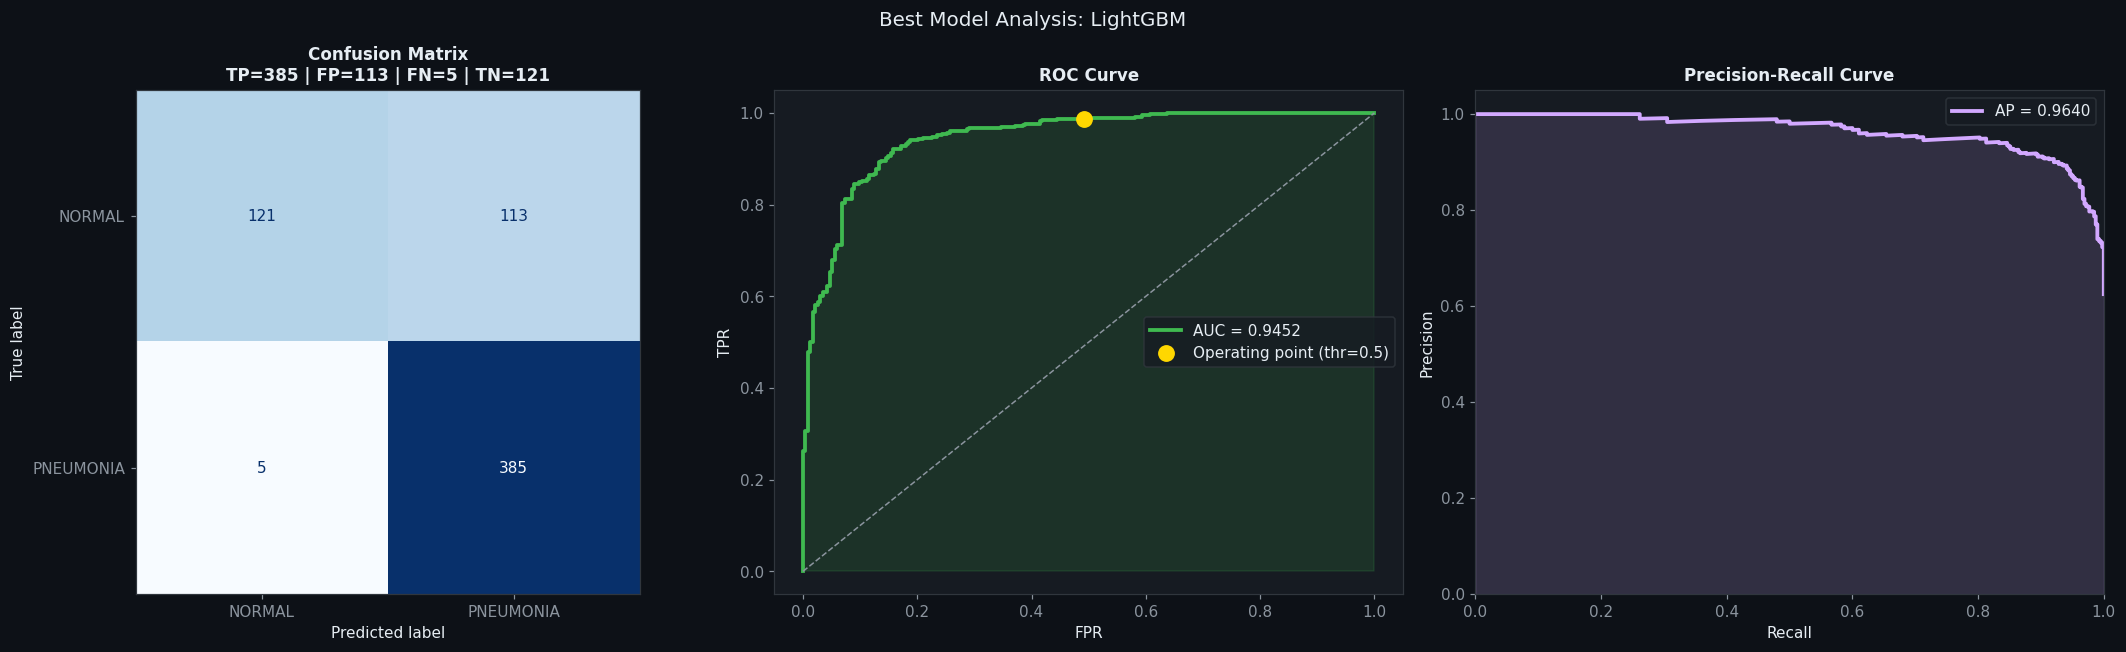

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle(f"Best Model Analysis: {BEST_ML_NAME}", fontsize=13)

# Confusion matrix
cm = confusion_matrix(y_te, BEST_ML_RES["y_pred"])
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
    ax=axes[0], colorbar=False, cmap="Blues")
tn, fp, fn, tp = cm.ravel()
axes[0].set_title(f"Confusion Matrix\nTP={tp} | FP={fp} | FN={fn} | TN={tn}")

# ROC curve
fpr, tpr, thrs = roc_curve(y_te, BEST_ML_RES["y_prob"])
op = np.argmin(np.abs(thrs - 0.5))
axes[1].plot(fpr, tpr, color=PAL[2], lw=2.5,
             label=f"AUC = {BEST_ML_RES['auc']:.4f}")
axes[1].fill_between(fpr, tpr, alpha=0.15, color=PAL[2])
axes[1].plot(fpr[op], tpr[op], "o", color="#ffd700", ms=10,
             label="Operating point (thr=0.5)")
axes[1].plot([0,1],[0,1], color=MUTED, lw=1, linestyle="--")
axes[1].set_title("ROC Curve"); axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR")
axes[1].legend()

# Precision-Recall curve
prec, rec_arr, _ = precision_recall_curve(y_te, BEST_ML_RES["y_prob"])
ap = average_precision_score(y_te, BEST_ML_RES["y_prob"])
axes[2].plot(rec_arr, prec, color=PAL[3], lw=2.5, label=f"AP = {ap:.4f}")
axes[2].fill_between(rec_arr, prec, alpha=0.15, color=PAL[3])
axes[2].set_title("Precision-Recall Curve")
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision")
axes[2].legend(); axes[2].set_xlim([0,1]); axes[2].set_ylim([0, 1.05])

plt.tight_layout()
plt.savefig("best_model_detail.png", dpi=120, bbox_inches="tight", facecolor=BG)
plt.show()

# CALIBRATION ANALYSIS

Calibration analysis examines how predicted probabilities relate to observed outcomes. This provides information about probability quality in addition to classification accuracy.


THRESHOLD OPTIMISATION — Clinical Operating Point

  Default threshold (0.50):
    Sensitivity (Recall)  : 0.9872
    Specificity           : 0.5171
    False Negatives       : 5  ← missed Pneumonia cases

  Optimal threshold (0.9999) — Youden's J:
    Sensitivity (Recall)  : 0.9205
    Specificity           : 0.8419
    False Negatives       : 31  ← missed Pneumonia cases
    Youden's J            : 0.7624

  Using threshold 0.9999 reduces missed Pneumonia by -26 cases vs default 0.5.

  AUC 95% CI (bootstrap, n=1000): 0.9452  [0.9265 – 0.9621]


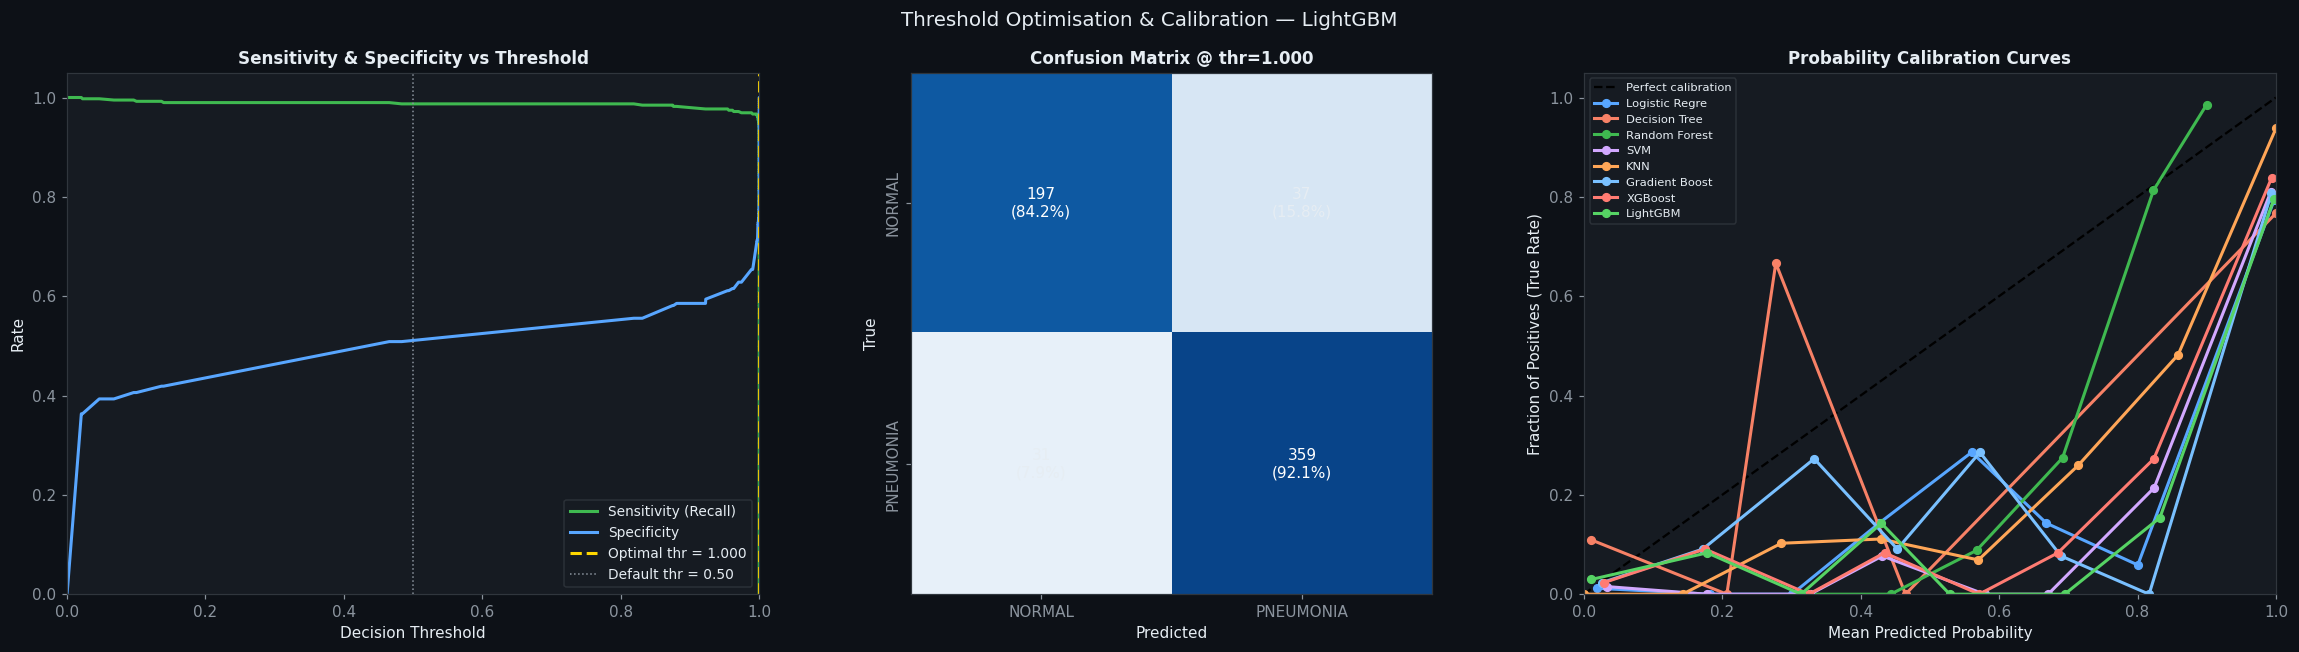


Optimal threshold identified: 0.9999
 AUC-ROC: 0.9452  [95% CI: 0.9265–0.9621]


In [ ]:
from sklearn.calibration import calibration_curve

print("=" * 65)
print("THRESHOLD OPTIMISATION — Clinical Operating Point")
print("=" * 65)

# Find optimal threshold using Youden's J statistic
fpr_opt, tpr_opt, thresholds_opt = roc_curve(y_te, BEST_ML_RES["y_prob"])
j_scores  = tpr_opt - fpr_opt
best_idx  = np.argmax(j_scores)
OPT_THRESH = float(thresholds_opt[best_idx])
y_pred_opt = (BEST_ML_RES["y_prob"] >= OPT_THRESH).astype(int)
tn_o, fp_o, fn_o, tp_o = confusion_matrix(y_te, y_pred_opt).ravel()

print(f"\n  Default threshold (0.50):")
tn_d, fp_d, fn_d, tp_d = confusion_matrix(y_te, BEST_ML_RES["y_pred"]).ravel()
print(f"    Sensitivity (Recall)  : {tp_d/(tp_d+fn_d):.4f}")
print(f"    Specificity           : {tn_d/(tn_d+fp_d):.4f}")
print(f"    False Negatives       : {fn_d}  ← missed Pneumonia cases")

print(f"\n  Optimal threshold ({OPT_THRESH:.4f}) — Youden's J:")
print(f"    Sensitivity (Recall)  : {tp_o/(tp_o+fn_o):.4f}")
print(f"    Specificity           : {tn_o/(tn_o+fp_o):.4f}")
print(f"    False Negatives       : {fn_o}  ← missed Pneumonia cases")
print(f"    Youden's J            : {j_scores[best_idx]:.4f}")
print(f"\n  Using threshold {OPT_THRESH:.4f} reduces missed Pneumonia by "
      f"{fn_d - fn_o} cases vs default 0.5.")

# AUC 95% Confidence Interval (bootstrap)
from sklearn.utils import resample as sk_resample
def bootstrap_auc_ci(y_true, y_prob, n=1000, seed=42):
    rng  = np.random.RandomState(seed)
    aucs = []
    for _ in range(n):
        idx = sk_resample(np.arange(len(y_true)), random_state=rng.randint(1e6))
        # Convert y_true to a numpy array for proper indexing
        if len(np.unique(np.array(y_true)[idx])) < 2:
            continue
        aucs.append(roc_auc_score(np.array(y_true)[idx], y_prob[idx]))
    return np.percentile(aucs, [2.5, 97.5])

# Pass y_te as a numpy array
ci_lo, ci_hi = bootstrap_auc_ci(np.array(y_te), BEST_ML_RES["y_prob"])
print(f"\n  AUC 95% CI (bootstrap, n=1000): "
      f"{BEST_ML_RES['auc']:.4f}  [{ci_lo:.4f} – {ci_hi:.4f}]")

# 3. Visualisations
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
fig.suptitle(f"Threshold Optimisation & Calibration — {BEST_ML_NAME}", fontsize=13)
# Panel A: Sensitivity / Specificity vs Threshold
ax = axes[0]
ax.plot(thresholds_opt, tpr_opt, color=PAL[2], lw=2,  label="Sensitivity (Recall)")
ax.plot(thresholds_opt, 1 - fpr_opt, color=PAL[0], lw=2, label="Specificity")
ax.axvline(OPT_THRESH, color="#ffd700", lw=2, linestyle="--",
           label=f"Optimal thr = {OPT_THRESH:.3f}")
ax.axvline(0.5, color=MUTED, lw=1, linestyle=":", label="Default thr = 0.50")
ax.set_title("Sensitivity & Specificity vs Threshold")
ax.set_xlabel("Decision Threshold"); ax.set_ylabel("Rate")
ax.legend(fontsize=9); ax.set_xlim([0, 1]); ax.set_ylim([0, 1.05])

# Panel B: Confusion matrix at optimal threshold
ax = axes[1]
cm_opt = confusion_matrix(y_te, y_pred_opt)
cm_n   = cm_opt.astype("float") / cm_opt.sum(axis=1)[:, np.newaxis]
ax.imshow(cm_n, cmap="Blues", vmin=0, vmax=1)
ax.set_title(f"Confusion Matrix @ thr={OPT_THRESH:.3f}")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(CLASSES); ax.set_yticklabels(CLASSES, rotation=90, va="center")
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for r in range(2):
    for c in range(2):
        ax.text(c, r, f"{cm_opt[r,c]}\n({cm_n[r,c]:.1%})",
                ha="center", va="center", fontsize=10,
                color="white" if cm_n[r,c] > 0.5 else TXT)

# Panel C: Calibration curves for all ML models
ax = axes[2]
ax.plot([0, 1], [0, 1], "k--", lw=1.5, label="Perfect calibration")
for i, (name, res) in enumerate(ML_RESULTS.items()):
    try:
        prob_true, prob_pred = calibration_curve(y_te, res["y_prob"], n_bins=8)
        ax.plot(prob_pred, prob_true, color=PAL[i % len(PAL)],
                lw=2, marker="o", ms=5, label=name[:14])
    except Exception:
        pass
ax.set_title("Probability Calibration Curves")
ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Fraction of Positives (True Rate)")
ax.legend(fontsize=7.5, loc="upper left"); ax.set_xlim([0, 1]); ax.set_ylim([0, 1.05])

plt.tight_layout()
plt.savefig("figures/threshold_calibration.png", dpi=120, bbox_inches="tight", facecolor=BG)
plt.show()

print(f"\nOptimal threshold identified: {OPT_THRESH:.4f}")
print(f" AUC-ROC: {BEST_ML_RES['auc']:.4f}  [95% CI: {ci_lo:.4f}–{ci_hi:.4f}]")

# MODEL EXPLAINABILITY OVERVIEW

This section prepares the explainability analysis for the selected classical ML model and its PCA-based feature representation.


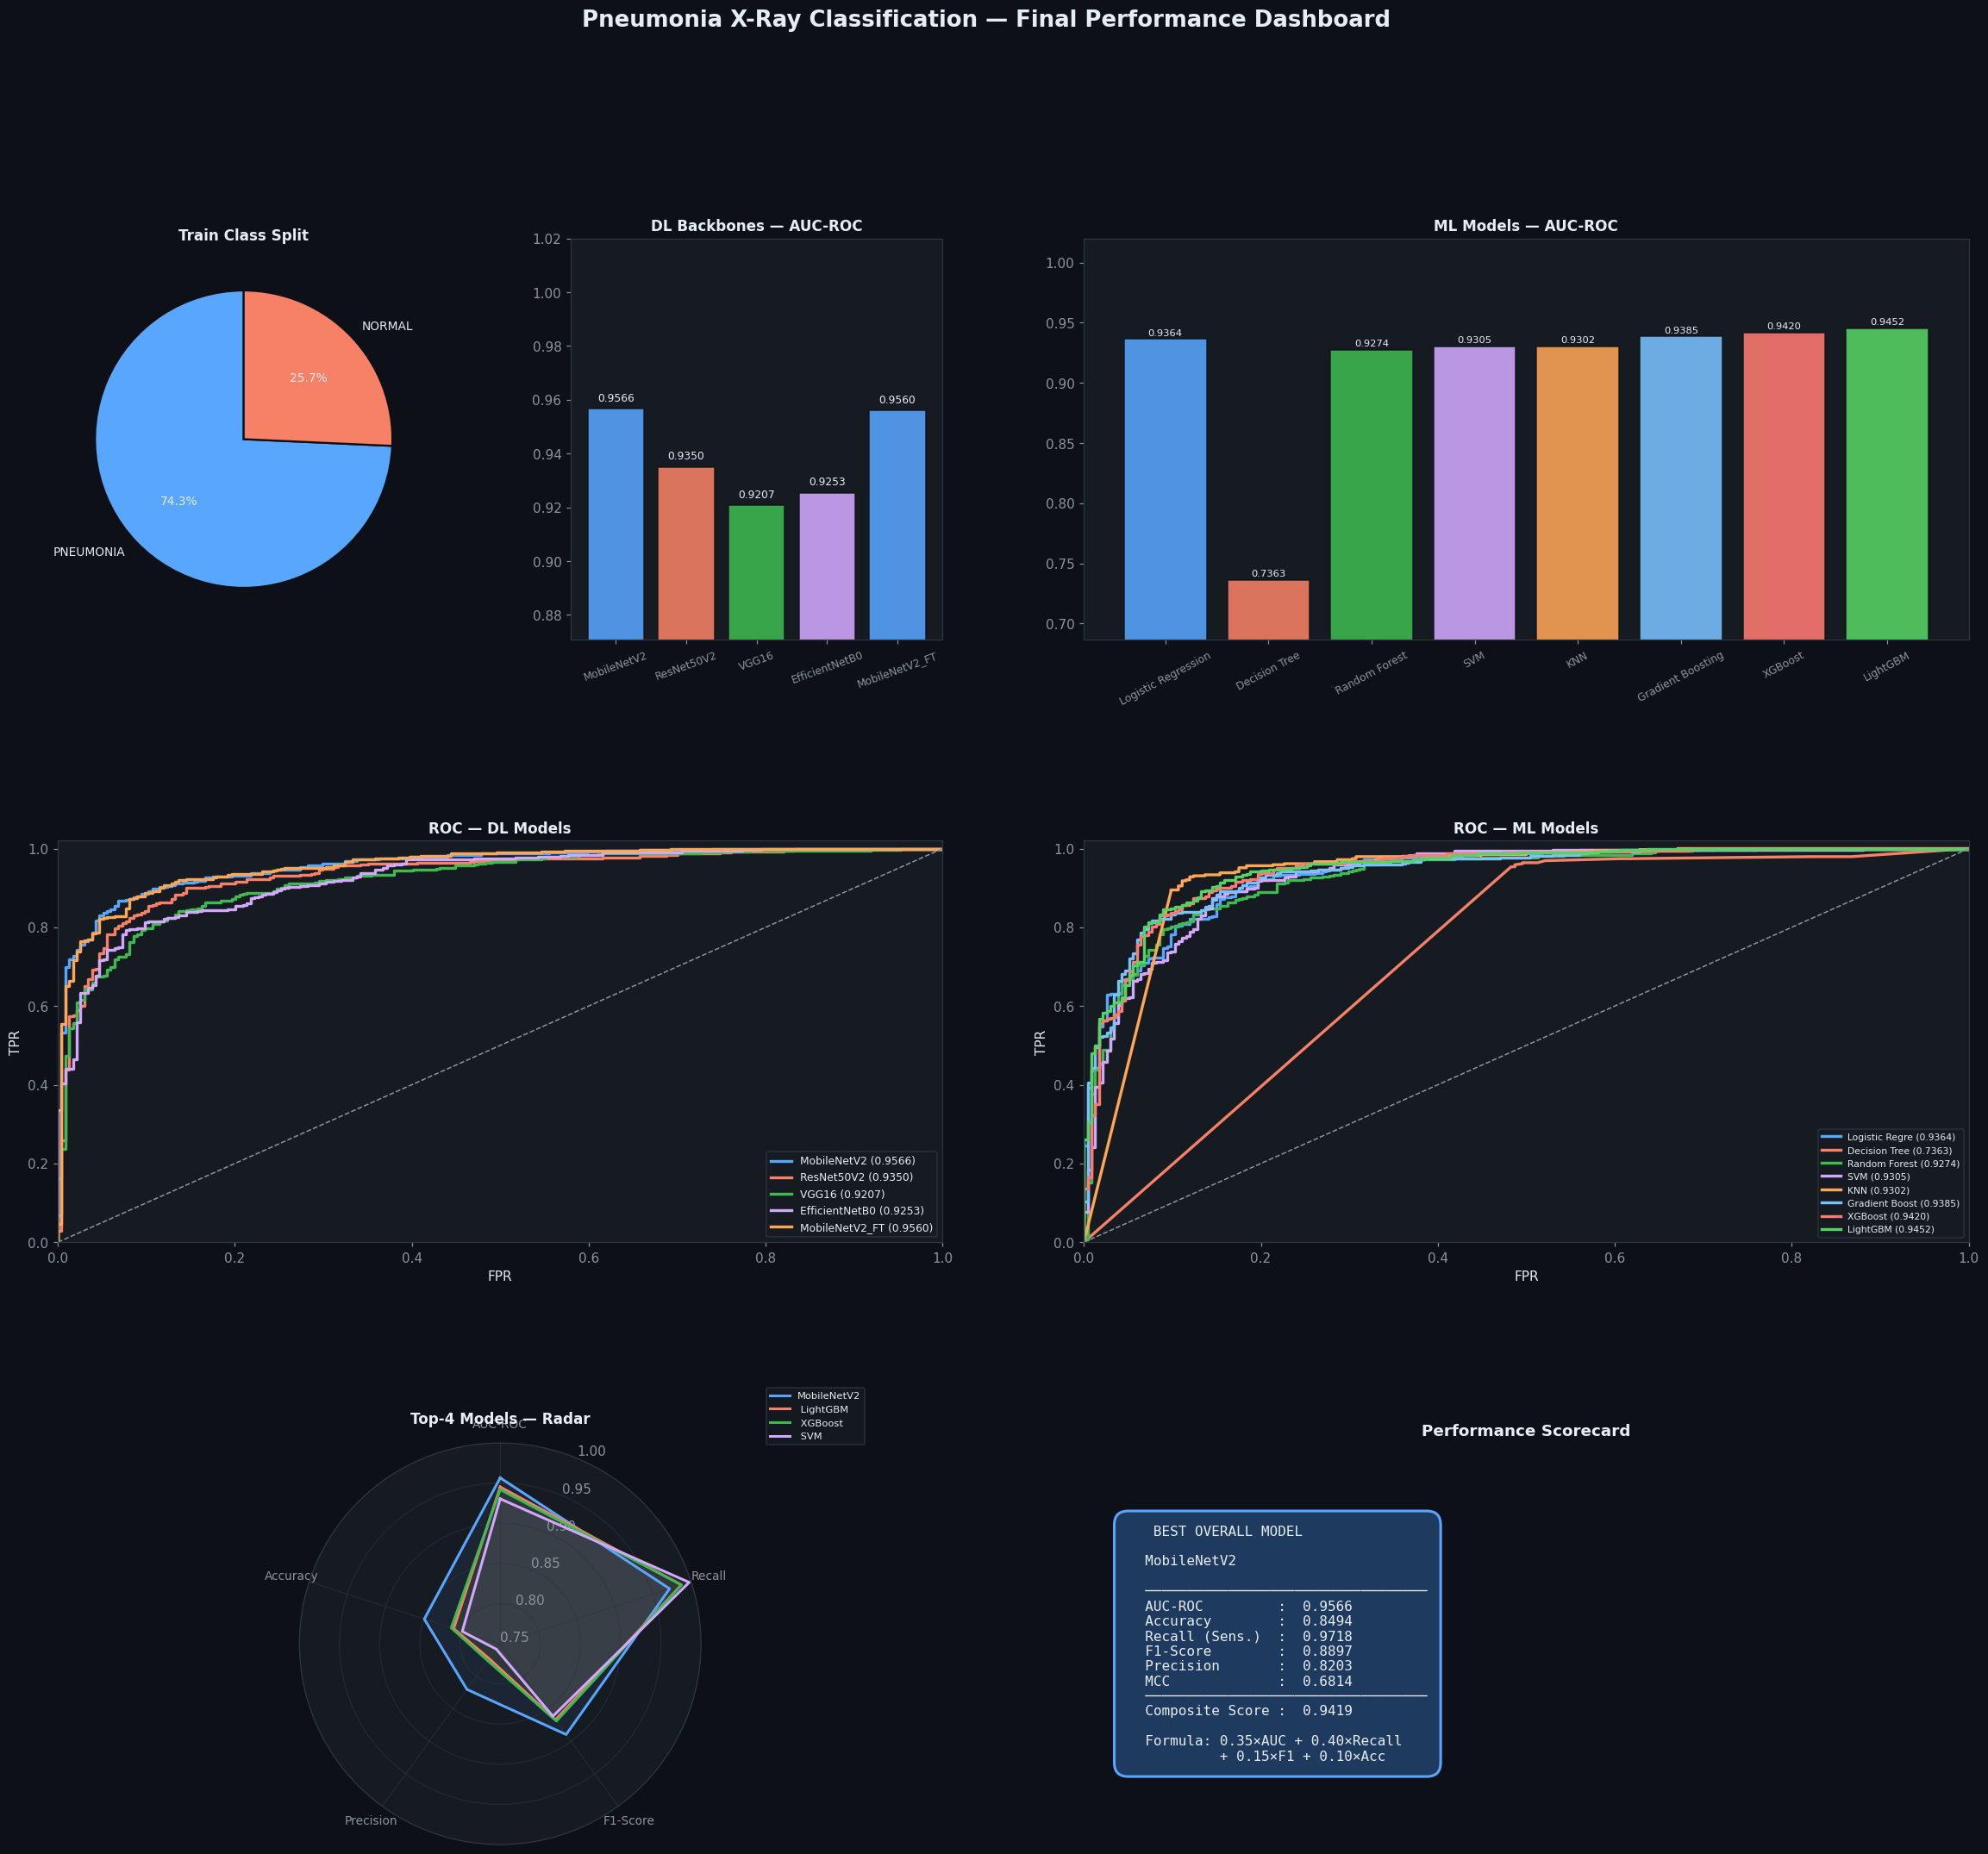

Final dashboard saved → final_dashboard.png


In [ ]:
fig = plt.figure(figsize=(26, 22))
fig.patch.set_facecolor(BG)
gs  = gridspec.GridSpec(3, 4, figure=fig, hspace=0.50, wspace=0.38)
fig.suptitle(" Pneumonia X-Ray Classification — Final Performance Dashboard",
             fontsize=17, fontweight="bold", color=TXT, y=0.99)

# 1. Dataset pie
ax1 = fig.add_subplot(gs[0, 0])
tc  = df_train.label.value_counts()
ax1.pie(tc, labels=tc.index, colors=[PAL[0], PAL[1]],
        autopct="%1.1f%%", startangle=90,
        textprops={"color": TXT, "fontsize": 9},
        wedgeprops={"edgecolor": BG, "linewidth": 1.5})
ax1.set_title("Train Class Split", color=TXT, pad=10)

# 2. DL AUC bars
ax2  = fig.add_subplot(gs[0, 1])
dl_n = list(DL_RESULTS.keys())
dl_a = [DL_RESULTS[n]["auc"] for n in dl_n]
bars = ax2.bar(dl_n, dl_a, color=PAL[:4], alpha=0.88, edgecolor=BG)
ax2.set_ylim([min(dl_a)-0.05, 1.02])
ax2.set_title("DL Backbones — AUC-ROC", color=TXT)
ax2.tick_params(axis="x", rotation=20, labelsize=8)
for b, v in zip(bars, dl_a):
    ax2.text(b.get_x()+b.get_width()/2, b.get_height()+0.003,
             f"{v:.4f}", ha="center", fontsize=8, color=TXT)

# 3. ML AUC bars
ax3  = fig.add_subplot(gs[0, 2:])
ml_n = list(ML_RESULTS.keys())
ml_a = [ML_RESULTS[n]["auc"] for n in ml_n]
bars = ax3.bar(ml_n, ml_a,
               color=[PAL[i%len(PAL)] for i in range(len(ml_n))],
               alpha=0.88, edgecolor=BG)
ax3.set_ylim([min(ml_a)-0.05, 1.02])
ax3.set_title("ML Models — AUC-ROC", color=TXT)
ax3.tick_params(axis="x", rotation=28, labelsize=8)
for b, v in zip(bars, ml_a):
    ax3.text(b.get_x()+b.get_width()/2, b.get_height()+0.003,
             f"{v:.4f}", ha="center", fontsize=7.5, color=TXT)

# 4. ROC — DL models
ax4 = fig.add_subplot(gs[1, :2])
for i, (name, res) in enumerate(DL_RESULTS.items()):
    fpr, tpr, _ = roc_curve(res["y_true"], res["y_prob"])
    ax4.plot(fpr, tpr, color=PAL[i], lw=2.2,
             label=f"{name} ({res['auc']:.4f})")
ax4.plot([0,1],[0,1], color=MUTED, lw=1, linestyle="--")
ax4.set_title("ROC — DL Models", color=TXT)
ax4.set_xlabel("FPR"); ax4.set_ylabel("TPR")
ax4.legend(fontsize=8, loc="lower right")
ax4.set_xlim([0,1]); ax4.set_ylim([0, 1.02])

# 5. ROC — ML models
ax5 = fig.add_subplot(gs[1, 2:])
for i, (name, res) in enumerate(ML_RESULTS.items()):
    fpr, tpr, _ = roc_curve(y_te, res["y_prob"])
    ax5.plot(fpr, tpr, color=PAL[i%len(PAL)], lw=2.2,
             label=f"{name[:14]} ({res['auc']:.4f})")
ax5.plot([0,1],[0,1], color=MUTED, lw=1, linestyle="--")
ax5.set_title("ROC — ML Models", color=TXT)
ax5.set_xlabel("FPR"); ax5.set_ylabel("TPR")
ax5.legend(fontsize=7, loc="lower right")
ax5.set_xlim([0,1]); ax5.set_ylim([0, 1.02])

# 6. Radar chart — top 4 models
ax6     = fig.add_subplot(gs[2, :2], polar=True)
rm      = ["AUC-ROC","Recall","F1-Score","Precision","Accuracy"]
NR      = len(rm)
angles  = [n/NR*2*np.pi for n in range(NR)] + [0]
ax6.set_theta_offset(np.pi/2); ax6.set_theta_direction(-1)
ax6.set_xticks(angles[:-1])
ax6.set_xticklabels(rm, fontsize=9, color=MUTED)
ax6.set_ylim([0.75, 1.0])
ax6.set_title("Top-4 Models — Radar", color=TXT, pad=15)
for i, (idx, row) in enumerate(CMP_DF_SORTED.head(4).iterrows()):
    vals = [float(row[m]) for m in rm] + [float(row[rm[0]])]
    ax6.plot(angles, vals, color=PAL[i], lw=2, label=idx[:22])
    ax6.fill(angles, vals, color=PAL[i], alpha=0.08)
ax6.legend(loc="upper right", bbox_to_anchor=(1.42, 1.15), fontsize=7.5)

# 7. Scorecard
ax7 = fig.add_subplot(gs[2, 2:])
ax7.axis("off")
br  = CMP_DF_SORTED.iloc[0]
card = (
    f"   BEST OVERALL MODEL\n\n"
    f"  {BEST_MODEL_NAME}\n\n"
    f"  {'─'*34}\n"
    f"  AUC-ROC         :  {float(br['AUC-ROC']):.4f}\n"
    f"  Accuracy        :  {float(br['Accuracy']):.4f}\n"
    f"  Recall (Sens.)  :  {float(br['Recall']):.4f}\n"
    f"  F1-Score        :  {float(br['F1-Score']):.4f}\n"
    f"  Precision       :  {float(br['Precision']):.4f}\n"
    f"  MCC             :  {float(br['MCC']):.4f}\n"
    f"  {'─'*34}\n"
    f"  Composite Score :  {float(br['Composite Score']):.4f}\n\n"
    f"  Formula: 0.35×AUC + 0.40×Recall\n"
    f"           + 0.15×F1 + 0.10×Acc"
)
ax7.text(0.05, 0.5, card, transform=ax7.transAxes,
         fontsize=10.5, color=TXT, va="center", fontfamily="monospace",
         bbox=dict(boxstyle="round,pad=1.0", facecolor="#1f3a5f",
                   edgecolor="#58a6ff", linewidth=2))
ax7.set_title("Performance Scorecard", color=TXT, fontsize=12)

plt.savefig("final_dashboard.png", dpi=140, bbox_inches="tight", facecolor=BG)
plt.show()
print("Final dashboard saved → final_dashboard.png")

#  SHAP EXPLAINABILITY

SHAP (SHapley Additive exPlanations) is used to estimate how individual PCA features contribute to model predictions. The exact explainer depends on the selected classifier.


In [ ]:
print(f"Computing SHAP for: {BEST_ML_NAME}")
feat_names = [f"PC{i+1}" for i in range(X_te_pca.shape[1])]

if hasattr(BEST_ML_CLF, "feature_importances_"):
    explainer = shap.TreeExplainer(BEST_ML_CLF)
    shap_vals = explainer.shap_values(X_te_pca)
    if isinstance(shap_vals, list):
        shap_vals = shap_vals[1]
    exp_val = (explainer.expected_value[1]
               if isinstance(explainer.expected_value, (list, np.ndarray))
               else explainer.expected_value)
else:
    bg       = shap.sample(X_ml_pca, 150, random_state=SEED)
    explainer = shap.KernelExplainer(BEST_ML_CLF.predict_proba, bg)
    shap_vals = explainer.shap_values(X_te_pca[:300], nsamples=100)
    if isinstance(shap_vals, list):
        shap_vals = shap_vals[1]
    exp_val = (explainer.expected_value[1]
               if isinstance(explainer.expected_value, (list, np.ndarray))
               else explainer.expected_value)

print(f"  SHAP values shape: {np.array(shap_vals).shape}")
print(f"  Expected value   : {exp_val:.4f}")
print(" SHAP values computed.")

Computing SHAP for: LightGBM
  SHAP values shape: (624, 741)
  Expected value   : 8.0933
 SHAP values computed.


# SHAP SUMMARY / BEESWARM

The SHAP summary visualization shows the distribution and magnitude of feature contributions across samples.


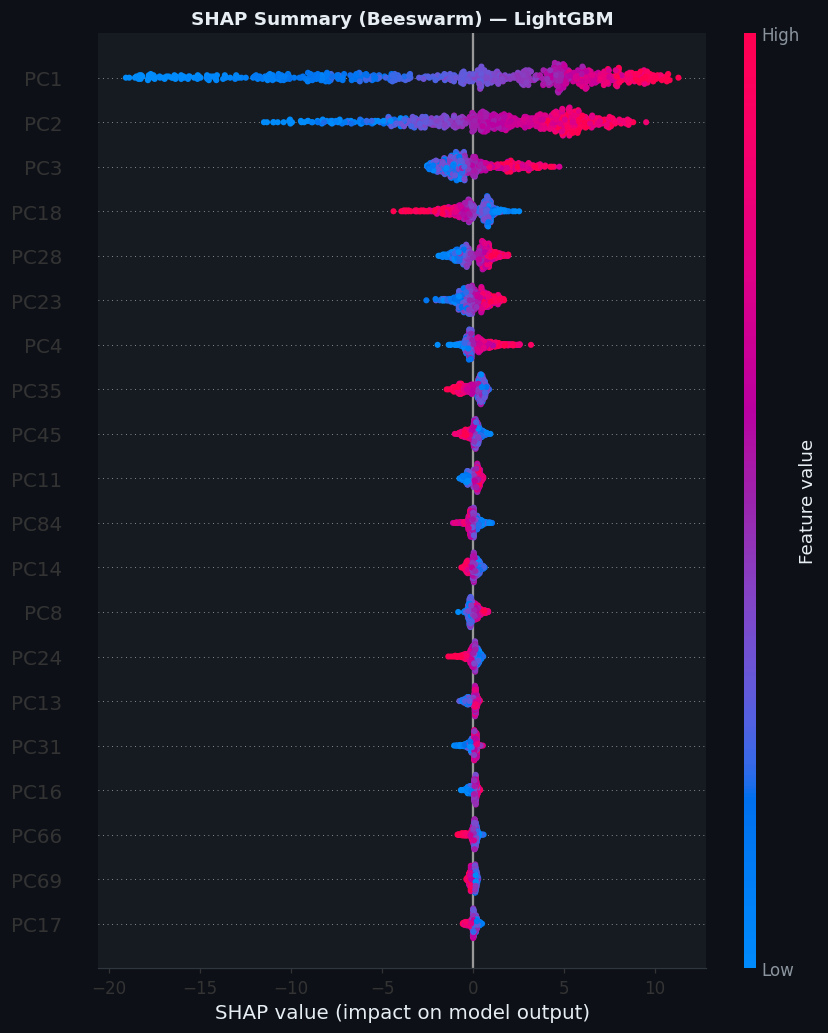

Each dot = one test sample. X-axis = SHAP impact on Pneumonia probability.
 Red = high feature value · Blue = low feature value.


In [ ]:
# SHAP Summary — Beeswarm
plt.figure(figsize=(11, 7))
shap.summary_plot(shap_vals, X_te_pca, feature_names=feat_names,
                  max_display=20, show=False, plot_type="dot")
plt.title(f"SHAP Summary (Beeswarm) — {BEST_ML_NAME}",
          fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("shap_beeswarm.png", dpi=120, bbox_inches="tight")
plt.show()
print("Each dot = one test sample. X-axis = SHAP impact on Pneumonia probability.")
print(" Red = high feature value · Blue = low feature value.")

#SHAP GLOBAL FEATURE IMPORTANCE

The SHAP bar plot summarizes global feature importance based on the absolute contribution values.


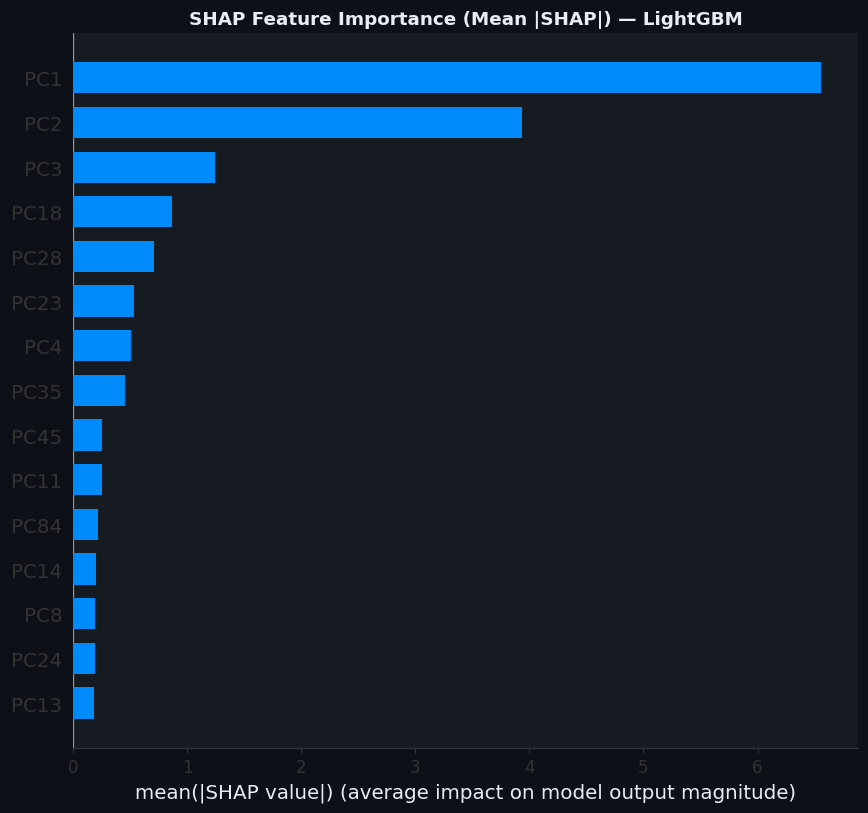

In [ ]:
# SHAP Bar — Global Importance
plt.figure(figsize=(11, 6))
shap.summary_plot(shap_vals, X_te_pca, feature_names=feat_names,max_display=15, plot_type="bar", show=False)
plt.title(f"SHAP Feature Importance (Mean |SHAP|) — {BEST_ML_NAME}",fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("shap_bar.png", dpi=120, bbox_inches="tight")
plt.show()

# CASE-LEVEL SHAP ANALYSIS

Representative true-positive, true-negative, false-positive, and false-negative cases are examined using SHAP force plots when such cases exist in the test set.



✅ True Positive  — Pneumonia Correctly Flagged
   True: PNEUMONIA  Pred: PNEUMONIA  P(Pneumonia)=1.0000


<Figure size 1540x330 with 0 Axes>

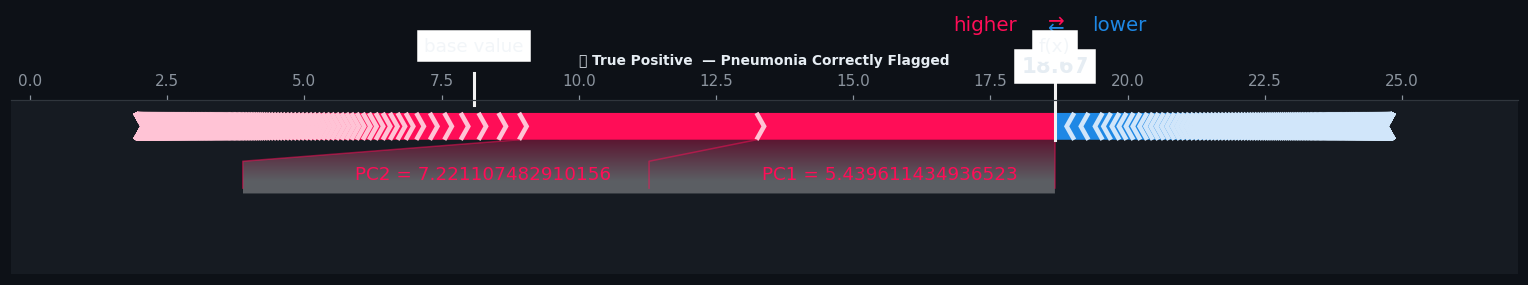


☑️ True Negative  — Normal Correctly Cleared
   True: NORMAL  Pred: NORMAL  P(Pneumonia)=0.4922


<Figure size 1540x330 with 0 Axes>

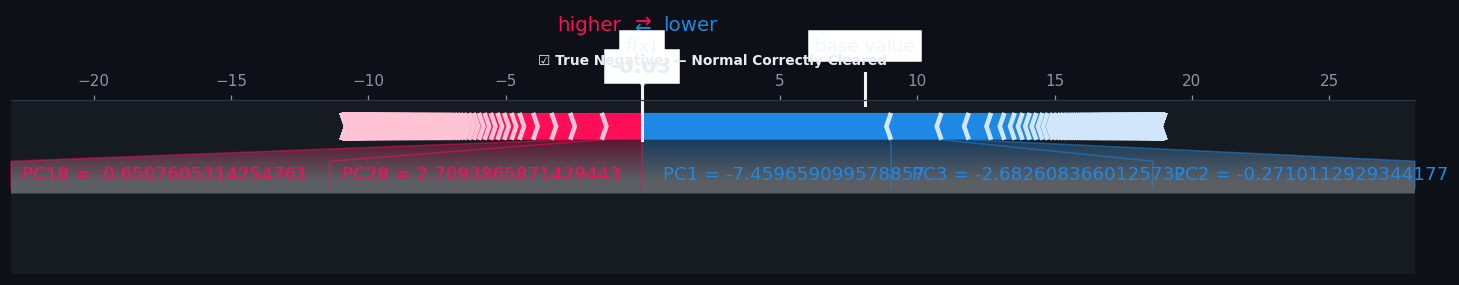


🚩 False Positive — Normal Incorrectly Flagged
   True: NORMAL  Pred: PNEUMONIA  P(Pneumonia)=1.0000


<Figure size 1540x330 with 0 Axes>

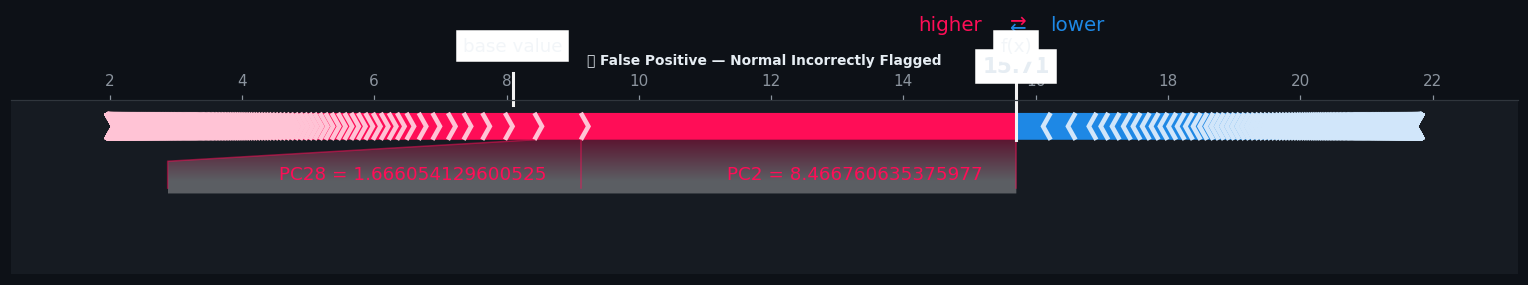


🔴 False Negative — Pneumonia Dangerously Missed
   True: PNEUMONIA  Pred: NORMAL  P(Pneumonia)=0.0206


<Figure size 1540x330 with 0 Axes>

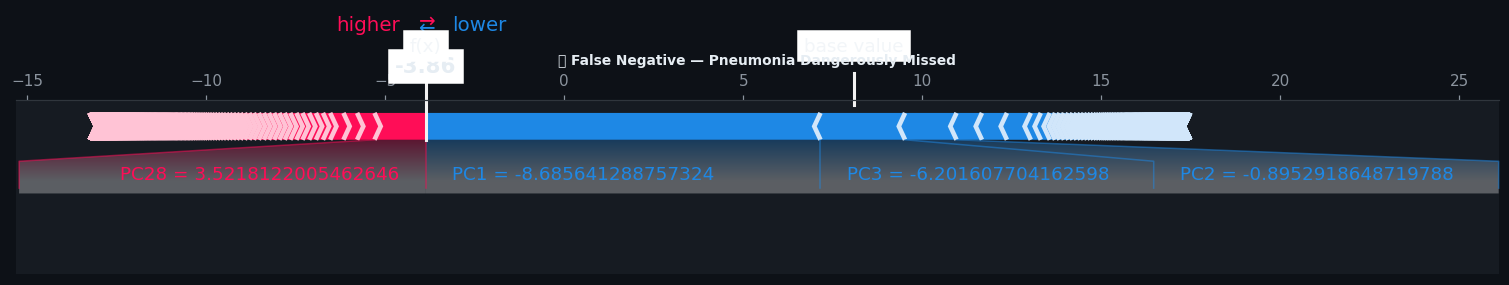

In [ ]:
y_pred_arr = np.array(BEST_ML_RES["y_pred"])
y_prob_arr = np.array(BEST_ML_RES["y_prob"])
y_te_arr = np.array(y_te)

INV_LABEL = {v: k for k, v in LABEL_MAP.items()}

cases_definitions = [
    ("True Positive  — Pneumonia Correctly Flagged",    (y_te_arr==1) & (y_pred_arr==1), "✅"),
    ("True Negative  — Normal Correctly Cleared",       (y_te_arr==0) & (y_pred_arr==0), "☑️"),
    ("False Positive — Normal Incorrectly Flagged",     (y_te_arr==0) & (y_pred_arr==1), "🚩"),
    ("False Negative — Pneumonia Dangerously Missed",   (y_te_arr==1) & (y_pred_arr==0), "🔴"),
]
processed_cases = []
for title, condition, icon in cases_definitions:
    indices = np.where(condition)[0]
    if len(indices) > 0:
        processed_cases.append((title, indices[0], icon))
    else:
        print(f"\n{icon} {title} (No samples of this type found in the test set, skipping force plot).")

for title, idx, icon in processed_cases:
    print(f"\n{icon} {title}")
    print(f"   True: {INV_LABEL[y_te_arr[idx]]}  "
          f"Pred: {INV_LABEL[y_pred_arr[idx]]}  "
          f"P(Pneumonia)={y_prob_arr[idx]:.4f}")
    plt.figure(figsize=(14, 3))
    shap.force_plot(exp_val, shap_vals[idx], X_te_pca[idx],
                    feature_names=feat_names, matplotlib=True,
                    show=False, figsize=(14, 3))
    plt.title(f"{icon} {title}", fontsize=9)
    plt.tight_layout()
    plt.savefig(f"shap_force_{idx}.png", dpi=100, bbox_inches="tight")
    plt.show()

# FINAL PROJECT INTERPRETATION

The final section below summarizes the actual experiment using values generated during notebook execution. It does not hard-code performance numbers.


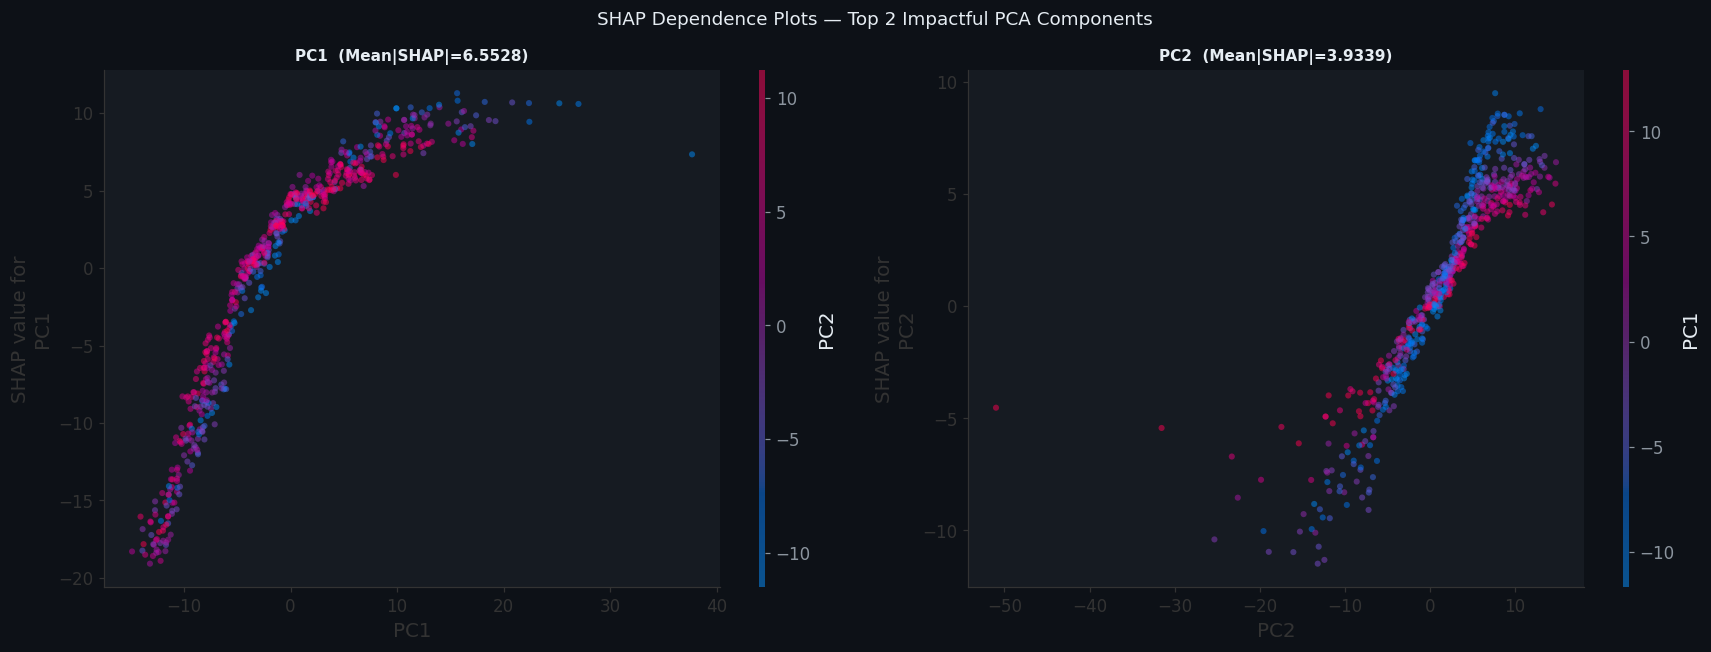

 PC1 has the highest predictive influence on LightGBM.


In [ ]:
# SHAP Dependence — Top 2 PCA components
mean_abs = np.abs(shap_vals).mean(axis=0)
top2     = np.argsort(mean_abs)[::-1][:2]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("SHAP Dependence Plots — Top 2 Impactful PCA Components", fontsize=12)
for i, pc_idx in enumerate(top2):
    shap.dependence_plot(pc_idx, shap_vals, X_te_pca,
                         feature_names=feat_names, ax=axes[i],
                         show=False, alpha=0.5)
    axes[i].set_title(
        f"{feat_names[pc_idx]}  (Mean|SHAP|={mean_abs[pc_idx]:.4f})", fontsize=10)
plt.tight_layout()
plt.savefig("shap_dependence.png", dpi=120, bbox_inches="tight")
plt.show()
print(f" {feat_names[top2[0]]} has the highest predictive influence on {BEST_ML_NAME}.")

#  CONCLUSION

The project implements an end-to-end chest X-ray classification workflow covering data validation, exploratory analysis, image augmentation, transfer learning, fine-tuning, CNN feature extraction, PCA, classical machine learning, evaluation, and explainability.

The conclusion should be based on the metrics printed by the notebook rather than assumed values. The next code cell automatically displays the final model comparison so the reported conclusion remains consistent with the actual run.

**Important:** This project is a machine-learning classification study. Its predictions should not be treated as a standalone medical diagnosis or as a substitute for assessment by qualified healthcare professionals.


# LIMITATIONS

### Dataset and Generalization
- The performance measured in this notebook depends on the available dataset and its train/validation/test split.
- Performance on an external hospital, scanner, population, or acquisition protocol may differ.
- Dataset imbalance or differences in image quality can affect evaluation.

### Model Limitations
- Transfer-learning models inherit limitations from their pretrained representations.
- PCA compresses the CNN feature representation and may discard some information.
- Classical ML results depend on the selected feature extractor and PCA configuration.
- SHAP explanations describe model behaviour; they do not prove that a highlighted feature is a medical cause.

### Clinical Limitation
The system is intended for academic/project use and should not be used as an independent diagnostic tool. Clinical decisions require appropriate medical expertise and additional patient information.





#  FUTURE SCOPE

Possible future improvements include:

- Validate the final model on an independent external dataset.
- Investigate additional transfer-learning architectures.
- Improve data augmentation and class-balancing strategies where appropriate.
- Perform more systematic hyperparameter optimization.
- Evaluate calibration and threshold selection for the intended application.
- Explore explainability directly in image space in addition to feature-level explanations.
- Build a controlled deployment pipeline with model/version tracking.
- Add clinical validation and appropriate safety evaluation before any real-world medical use.
